# <center>Hybrid Search RAG | Chapter 2 : Lexical vs Semantic Retrieval


This notebook is the **main learning resource** for Chapter 2.

You do **not** need to read a separate 40–50 page theory article before studying it.

The learning flow is:

```text
WHY
 ↓
ESSENTIAL THEORY
 ↓
DIAGRAM
 ↓
SMALL EXAMPLE
 ↓
STEP-BY-STEP CODE
 ↓
PRINT INTERNAL FLOW
 ↓
VISUALIZE
 ↓
FAILURE CASES
 ↓
PRODUCTION THINKING
 ↓
INTERVIEW + REVISION
```

### By the end, you should understand

- lexical / sparse retrieval
- semantic / dense retrieval
- vocabulary mismatch
- tokenization
- TF-IDF intuition
- embeddings
- cosine similarity
- exact IDs and error codes
- regulation/article numbers
- version and number sensitivity
- acronyms
- negation
- exact vs semantic vs mixed queries
- simple Hybrid Search
- score normalization
- alpha weighting
- retrieval evaluation
- retrieval debugging

---

## Main mental model

```text
LEXICAL SEARCH
"Do the WORDS match?"

SEMANTIC SEARCH
"Does the MEANING match?"

HYBRID SEARCH
"Use BOTH signals."
```

# 0. How to Use This Notebook

For every section:

1. Read the short theory.
2. Predict the result.
3. Run the code.
4. Read the printed values.
5. Look at the visual.
6. Answer the checkpoint.

Do not focus only on calling a library function.

The goal is to understand:

```text
INPUT
 ↓
INTERNAL REPRESENTATION
 ↓
SCORING
 ↓
RANKING
 ↓
OUTPUT
```

# 1. Setup

We use:

- `numpy` for vectors
- `pandas` for tables
- `matplotlib` for diagrams
- `scikit-learn` for TF-IDF, cosine similarity and PCA
- `sentence-transformers` for semantic embeddings

## What is a vector?

A vector is simply a list of numbers.

```text
[0.21, -0.42, 0.77, 0.11]
```

Search systems convert text into numerical representations so queries and documents can be compared mathematically.

In [1]:
# Uncomment if needed.
# %pip install -q numpy pandas matplotlib scikit-learn sentence-transformers

In [4]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA

# 1. Remove display limits for rows and columns
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

# Optional: Prevent cell content/long text from cutting off
pd.set_option('display.max_colwidth', None)


print("Imports complete.")

Imports complete.


# 2. Why Do We Need Two Retrieval Styles?

Imagine these documents:

```text
D1: REACH Article 33 requires suppliers to communicate SVHC information.

D2: European law requires companies to disclose harmful substances in products.

D3: Error E401 means authentication failure.

D4: Users who cannot sign in should reset expired credentials.
```

A user may search:

```text
REACH Article 33
```

This is an **exact query**.

Another user may ask:

```text
Why can't a user log in?
```

This is a **semantic query**.

One retrieval method is not equally good at both.

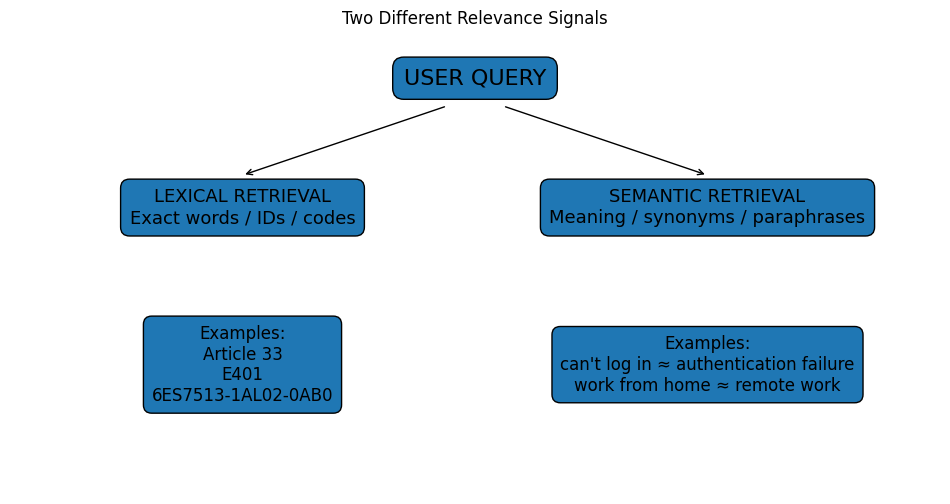

In [2]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.axis("off")

ax.text(
    0.5, 0.90, "USER QUERY",
    ha="center", va="center", fontsize=16,
    bbox=dict(boxstyle="round,pad=0.5")
)

ax.text(
    0.25, 0.62,
    "LEXICAL RETRIEVAL\nExact words / IDs / codes",
    ha="center", va="center", fontsize=13,
    bbox=dict(boxstyle="round,pad=0.5")
)

ax.text(
    0.75, 0.62,
    "SEMANTIC RETRIEVAL\nMeaning / synonyms / paraphrases",
    ha="center", va="center", fontsize=13,
    bbox=dict(boxstyle="round,pad=0.5")
)

ax.text(
    0.25, 0.28,
    "Examples:\nArticle 33\nE401\n6ES7513-1AL02-0AB0",
    ha="center", va="center", fontsize=12,
    bbox=dict(boxstyle="round,pad=0.5")
)

ax.text(
    0.75, 0.28,
    "Examples:\ncan't log in ≈ authentication failure\nwork from home ≈ remote work",
    ha="center", va="center", fontsize=12,
    bbox=dict(boxstyle="round,pad=0.5")
)

ax.annotate("", xy=(0.25, 0.69), xytext=(0.47, 0.84),
            arrowprops=dict(arrowstyle="->"))
ax.annotate("", xy=(0.75, 0.69), xytext=(0.53, 0.84),
            arrowprops=dict(arrowstyle="->"))

plt.title("Two Different Relevance Signals")
plt.show()

# 3. Build a Small Enterprise-Style Corpus

We intentionally include:

- legal references
- error codes
- product IDs
- policy wording
- software versions
- retention durations
- negation
- battery obligations

This allows us to reproduce real retrieval problems.

In [5]:
documents = [
    {"id": "D1", "category": "regulation",
     "text": "REACH Regulation EC 1907/2006 governs registration, evaluation, authorisation and restriction of chemical substances."},

    {"id": "D2", "category": "regulation",
     "text": "REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs."},

    {"id": "D3", "category": "regulation",
     "text": "REACH Article 34 contains separate information duties and is distinct from Article 33."},

    {"id": "D4", "category": "regulation",
     "text": "Regulation EU 2023/1542 establishes requirements for batteries and waste batteries."},

    {"id": "D5", "category": "regulation",
     "text": "Regulation EU 2025/40 establishes requirements for packaging and packaging waste."},

    {"id": "D6", "category": "support",
     "text": "Error code E401 indicates an authentication failure caused by invalid or expired credentials."},

    {"id": "D7", "category": "support",
     "text": "Users who cannot sign in should verify their login credentials and reset the password if required."},

    {"id": "D8", "category": "support",
     "text": "Error code E503 indicates that the service is temporarily unavailable."},

    {"id": "D9", "category": "product",
     "text": "Siemens product 6ES7513-1AL02-0AB0 is an industrial automation CPU."},

    {"id": "D10", "category": "product",
     "text": "Industrial automation controllers are selected based on processing capacity, communication interfaces and system requirements."},

    {"id": "D11", "category": "policy",
     "text": "Employees may work remotely for two days each week."},

    {"id": "D12", "category": "policy",
     "text": "The work-from-home allowance permits eligible employees to perform their duties away from the office."},

    {"id": "D13", "category": "software",
     "text": "Python 3.12 installation troubleshooting includes dependency checks and environment configuration."},

    {"id": "D14", "category": "software",
     "text": "Python 3.11 installation troubleshooting includes dependency checks and environment configuration."},

    {"id": "D15", "category": "retention",
     "text": "Records must be retained for 24 months."},

    {"id": "D16", "category": "retention",
     "text": "Records must be retained for 36 months."},

    {"id": "D17", "category": "compliance",
     "text": "Products containing substance X are prohibited."},

    {"id": "D18", "category": "compliance",
     "text": "Products containing substance X are not prohibited."},

    {"id": "D19", "category": "battery",
     "text": "Producers shall finance the collection and treatment of waste batteries."},

    {"id": "D20", "category": "battery",
     "text": "Battery fire safety guidance describes thermal runaway and emergency response procedures."}
]

df = pd.DataFrame(documents)

print("Total documents:", len(df))
display(df)

Total documents: 20


,id,category,text
0,D1,regulation,"REACH Regulation EC 1907/2006 governs registration, evaluation, authorisation and restriction of chemical substances."
1,D2,regulation,"REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs."
2,D3,regulation,REACH Article 34 contains separate information duties and is distinct from Article 33.
3,D4,regulation,Regulation EU 2023/1542 establishes requirements for batteries and waste batteries.
4,D5,regulation,Regulation EU 2025/40 establishes requirements for packaging and packaging waste.
5,D6,support,Error code E401 indicates an authentication failure caused by invalid or expired credentials.
6,D7,support,Users who cannot sign in should verify their login credentials and reset the password if required.
7,D8,support,Error code E503 indicates that the service is temporarily unavailable.
8,D9,product,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation CPU.
9,D10,product,"Industrial automation controllers are selected based on processing capacity, communication interfaces and system requirements."


# 4. Basic Retrieval Vocabulary

### Query
What the user searches.

```text
REACH Article 33
```

### Document
One searchable text unit.

### Corpus
All searchable documents.

### Token
A piece of text produced during tokenization.

```text
REACH Article 33
→ reach, article, 33
```

### Score
A number estimating relevance.

### Ranking
Documents sorted by score.

### Top-K
Return only the best K results.

### Retriever
The component that maps:

```text
query → relevant candidate documents
```

# 5. Lexical Retrieval — First Principles

Lexical retrieval focuses on actual terms.

For:

```text
REACH Article 33
```

the strongest clues are:

```text
REACH
Article
33
```

A lexical search engine does not need to understand what `33` means.

It only needs to observe:

```text
query contains 33
document contains 33
```

That is why lexical retrieval is excellent for exact references.

## 5.1 Tokenization

Search engines normally process text before indexing.

A simplified pipeline:

```text
Raw text
 ↓
Lowercase
 ↓
Split / tokenize
 ↓
Terms
```

In [7]:
def simple_tokenize(text):
    print("ORIGINAL:")
    print(text)

    lowered = text.lower()
    print("\nLOWERCASED:")
    print(lowered)

    tokens = re.findall(r"[a-z0-9]+", lowered)
    print("\nTOKENS:")
    #print(tokens)

    return tokens


simple_tokenize("REACH Article 33 requires suppliers.")

ORIGINAL:
REACH Article 33 requires suppliers.

LOWERCASED:
reach article 33 requires suppliers.

TOKENS:


['reach', 'article', '33', 'requires', 'suppliers']

## 5.2 Tokenization Can Affect IDs

Consider:

```text
6ES7513-1AL02-0AB0
```

A generic tokenizer may split it.

That can be problematic when the complete product code is meaningful as one identifier.

In [8]:
tokens = simple_tokenize("6ES7513-1AL02-0AB0")

print("\nFinal token list:")
print(tokens)

ORIGINAL:
6ES7513-1AL02-0AB0

LOWERCASED:
6es7513-1al02-0ab0

TOKENS:

Final token list:
['6es7513', '1al02', '0ab0']


In production, you may need special analyzers for:

```text
product IDs
CAS numbers
error codes
SKUs
regulation numbers
versions
URLs
```

# 6. Simplest Lexical Idea — Token Overlap

Before TF-IDF and BM25, understand the simplest relevance signal:

> How many query tokens also occur in the document?

In [9]:
def explain_token_overlap(query, document):
    query_tokens = set(re.findall(r"[a-z0-9]+", query.lower()))
    doc_tokens = set(re.findall(r"[a-z0-9]+", document.lower()))

    overlap = query_tokens.intersection(doc_tokens)

    print("QUERY:")
    print(query)

    print("\nDOCUMENT:")
    print(document)

    print("\nQUERY TOKENS:")
    print(query_tokens)

    print("\nDOCUMENT TOKENS:")
    print(doc_tokens)

    print("\nOVERLAP:")
    print(overlap)

    print("\nOVERLAP COUNT:")
    print(len(overlap))

    return overlap


doc_article_33 = df.loc[df["id"] == "D2", "text"].iloc[0]

explain_token_overlap(
    "REACH Article 33",
    doc_article_33
)

QUERY:
REACH Article 33

DOCUMENT:
REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.

QUERY TOKENS:
{'33', 'article', 'reach'}

DOCUMENT TOKENS:
{'suppliers', 'to', 'article', 'substances', 'information', 'commonly', 'very', 'concern', 'communicate', 'about', 'of', 'called', '33', 'requires', 'reach', 'high', 'svhcs'}

OVERLAP:
{'33', 'article', 'reach'}

OVERLAP COUNT:
3


{'33', 'article', 'reach'}

# 7. Vocabulary Mismatch

Now consider:

```text
Query:
work from home policy

Document:
Employees may work remotely for two days each week.
```

A human understands:

```text
work from home ≈ work remotely
```

But the exact vocabulary differs.

This is called **vocabulary mismatch**.

```text
MEANING matches
but
WORDS do not match well
```

In [10]:
remote_doc = df.loc[df["id"] == "D11", "text"].iloc[0]

explain_token_overlap(
    "work from home policy",
    remote_doc
)

QUERY:
work from home policy

DOCUMENT:
Employees may work remotely for two days each week.

QUERY TOKENS:
{'from', 'work', 'home', 'policy'}

DOCUMENT TOKENS:
{'remotely', 'days', 'work', 'each', 'employees', 'may', 'week', 'for', 'two'}

OVERLAP:
{'work'}

OVERLAP COUNT:
1


{'work'}

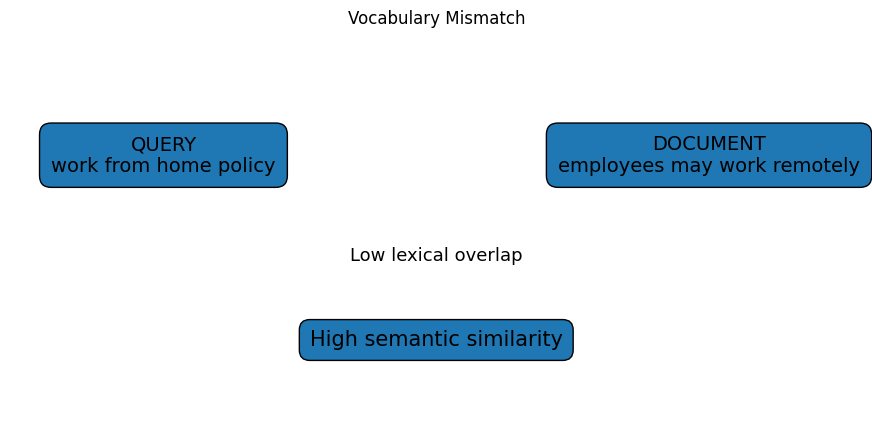

In [11]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.axis("off")

ax.text(
    0.18, 0.68,
    "QUERY\nwork from home policy",
    ha="center", va="center", fontsize=14,
    bbox=dict(boxstyle="round,pad=0.6")
)

ax.text(
    0.82, 0.68,
    "DOCUMENT\nemployees may work remotely",
    ha="center", va="center", fontsize=14,
    bbox=dict(boxstyle="round,pad=0.6")
)

ax.text(
    0.5, 0.42,
    "Low lexical overlap",
    ha="center", va="center", fontsize=13
)

ax.text(
    0.5, 0.20,
    "High semantic similarity",
    ha="center", va="center", fontsize=15,
    bbox=dict(boxstyle="round,pad=0.5")
)

plt.title("Vocabulary Mismatch")
plt.show()

# 8. TF-IDF — Better Lexical Weighting

Simple overlap treats every word equally.

But:

```text
information
```

is much less specific than:

```text
E401
```

TF-IDF gives more importance to useful terms.

For now remember:

```text
rare / discriminative term → higher importance
common term → lower importance
```

We will study TF-IDF mathematics in its dedicated chapter.

In [12]:
tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2)
)

tfidf_matrix = tfidf_vectorizer.fit_transform(
    df["text"].tolist()
)

print("TF-IDF matrix created.")
print("Rows = documents:", tfidf_matrix.shape[0])
print("Columns = lexical features:", tfidf_matrix.shape[1])
print("Shape:", tfidf_matrix.shape)

TF-IDF matrix created.
Rows = documents: 20
Columns = lexical features: 326
Shape: (20, 326)


If the matrix shape were:

```text
(20, 250)
```

that would mean:

```text
20 documents
250 possible lexical features
```

Most values are zero.

This is one reason lexical representations are called **sparse**.

In [14]:
feature_names = np.array(
    tfidf_vectorizer.get_feature_names_out()
)

print("First 40 learned features:")
print(feature_names[:100])

print("\nTotal number of features:")
print(len(feature_names))

First 40 learned features:
['0ab0' '0ab0 is' '11' '11 installation' '12' '12 installation' '1542'
 '1542 establishes' '1907' '1907 2006' '1al02' '1al02 0ab0' '2006'
 '2006 governs' '2023' '2023 1542' '2025' '2025 40' '24' '24 months' '33'
 '33 requires' '34' '34 contains' '36' '36 months' '40' '40 establishes'
 '6es7513' '6es7513 1al02' 'about' 'about substances' 'allowance'
 'allowance permits' 'an' 'an authentication' 'an industrial' 'and'
 'and emergency' 'and environment' 'and is' 'and packaging' 'and reset'
 'and restriction' 'and system' 'and treatment' 'and waste' 'are'
 'are not' 'are prohibited' 'are selected' 'article' 'article 33'
 'article 34' 'authentication' 'authentication failure' 'authorisation'
 'authorisation and' 'automation' 'automation controllers'
 'automation cpu' 'away' 'away from' 'based' 'based on' 'batteries'
 'batteries and' 'battery' 'battery fire' 'be' 'be retained' 'by'
 'by invalid' 'called' 'called svhcs' 'cannot' 'cannot sign' 'capacity'
 'capacity co

## 8.1 Inspect One Sparse Document Vector

We will print only non-zero TF-IDF features.

This lets you see what the vector actually contains.

In [15]:
doc_index = 1  # D2

row = tfidf_matrix[doc_index]

nonzero_indices = row.nonzero()[1]
nonzero_values = row.data

pairs = list(
    zip(
        feature_names[nonzero_indices],
        nonzero_values
    )
)

pairs = sorted(
    pairs,
    key=lambda x: x[1],
    reverse=True
)

print("DOCUMENT:")
print(df.iloc[doc_index]["text"])

print("\nNON-ZERO FEATURES:")

for term, weight in pairs[:25]:
    print(f"{term:<30} -> {weight:.4f}")

DOCUMENT:
REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.

NON-ZERO FEATURES:
requires                       -> 0.1806
suppliers                      -> 0.1806
communicate                    -> 0.1806
about                          -> 0.1806
very                           -> 0.1806
high                           -> 0.1806
concern                        -> 0.1806
commonly                       -> 0.1806
called                         -> 0.1806
svhcs                          -> 0.1806
33 requires                    -> 0.1806
requires suppliers             -> 0.1806
suppliers to                   -> 0.1806
to communicate                 -> 0.1806
communicate information        -> 0.1806
information about              -> 0.1806
about substances               -> 0.1806
substances of                  -> 0.1806
of very                        -> 0.1806
very high                      -> 0.1806
high concern             

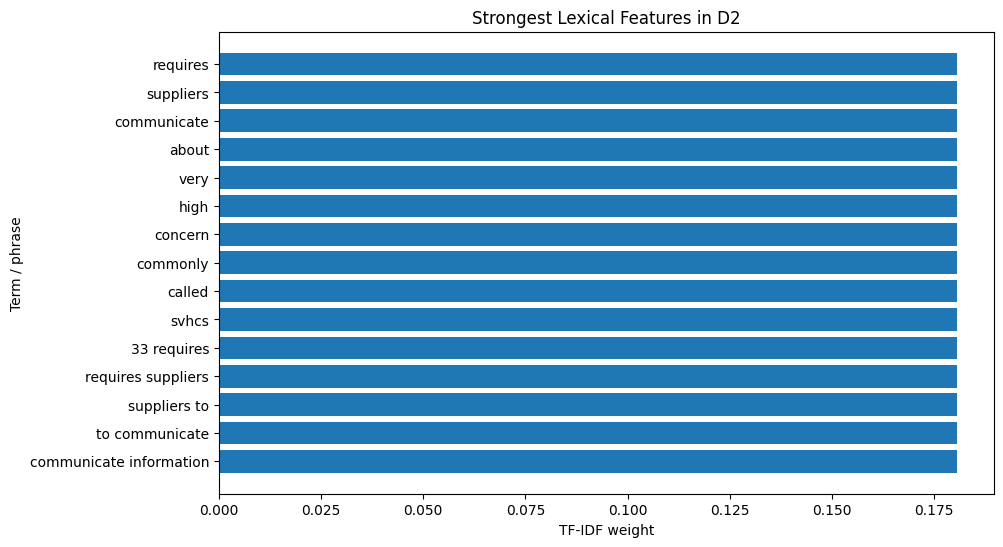

In [16]:
terms = [x[0] for x in pairs[:15]][::-1]
weights = [x[1] for x in pairs[:15]][::-1]

plt.figure(figsize=(10, 6))
plt.barh(terms, weights)
plt.xlabel("TF-IDF weight")
plt.ylabel("Term / phrase")
plt.title("Strongest Lexical Features in D2")
plt.show()

# 9. Sparse Search — Full Internal Flow

```text
Query
 ↓
TF-IDF vector
 ↓
Compare against document vectors
 ↓
Similarity scores
 ↓
Sort scores
 ↓
Top-K
```

In [17]:
def sparse_search_verbose(query, top_k=5):
    print("=" * 90)
    print("SPARSE / LEXICAL SEARCH")
    print("=" * 90)

    print("\nSTEP 1 — RAW QUERY")
    print(query)

    query_vector = tfidf_vectorizer.transform([query])

    print("\nSTEP 2 — QUERY VECTOR SHAPE")
    print(query_vector.shape)

    active_indices = query_vector.nonzero()[1]
    active_terms = feature_names[active_indices]
    active_weights = query_vector.data

    print("\nSTEP 3 — NON-ZERO QUERY FEATURES")

    if len(active_terms) == 0:
        print("No query features found.")
    else:
        for term, weight in zip(active_terms, active_weights):
            print(f"{term:<30} -> {weight:.4f}")

    scores = cosine_similarity(
        query_vector,
        tfidf_matrix
    ).flatten()

    print("\nSTEP 4 — SCORE FOR EVERY DOCUMENT")

    for i, score in enumerate(scores):
        print(f"{df.iloc[i]['id']}: {score:.4f}")

    ranked_indices = np.argsort(scores)[::-1]

    print("\nSTEP 5 — COMPLETE RANKING")

    for rank, idx in enumerate(ranked_indices, start=1):
        print(
            f"Rank {rank:>2}: "
            f"{df.iloc[idx]['id']} "
            f"score={scores[idx]:.4f}"
        )

    top_indices = ranked_indices[:top_k]

    results = df.iloc[top_indices].copy()
    results["sparse_score"] = scores[top_indices]

    print(f"\nSTEP 6 — FINAL TOP-{top_k}")
    display(
        results[
            ["id", "category", "text", "sparse_score"]
        ]
    )

    return results[
        ["id", "category", "text", "sparse_score"]
    ]

In [18]:
sparse_article = sparse_search_verbose(
    "REACH Article 33",
    top_k=5
)

SPARSE / LEXICAL SEARCH

STEP 1 — RAW QUERY
REACH Article 33

STEP 2 — QUERY VECTOR SHAPE
(1, 326)

STEP 3 — NON-ZERO QUERY FEATURES
33                             -> 0.4558
article                        -> 0.4558
article 33                     -> 0.4558
reach                          -> 0.4113
reach article                  -> 0.4558

STEP 4 — SCORE FOR EVERY DOCUMENT
D1: 0.0654
D2: 0.3483
D3: 0.4833
D4: 0.0000
D5: 0.0000
D6: 0.0000
D7: 0.0000
D8: 0.0000
D9: 0.0000
D10: 0.0000
D11: 0.0000
D12: 0.0000
D13: 0.0000
D14: 0.0000
D15: 0.0000
D16: 0.0000
D17: 0.0000
D18: 0.0000
D19: 0.0000
D20: 0.0000

STEP 5 — COMPLETE RANKING
Rank  1: D3 score=0.4833
Rank  2: D2 score=0.3483
Rank  3: D1 score=0.0654
Rank  4: D19 score=0.0000
Rank  5: D4 score=0.0000
Rank  6: D5 score=0.0000
Rank  7: D6 score=0.0000
Rank  8: D7 score=0.0000
Rank  9: D8 score=0.0000
Rank 10: D9 score=0.0000
Rank 11: D20 score=0.0000
Rank 12: D11 score=0.0000
Rank 13: D12 score=0.0000
Rank 14: D13 score=0.0000
Rank 15: D14 s

,id,category,text,sparse_score
2,D3,regulation,REACH Article 34 contains separate information duties and is distinct from Article 33.,0.483320
1,D2,regulation,"REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.",0.348277
0,D1,regulation,"REACH Regulation EC 1907/2006 governs registration, evaluation, authorisation and restriction of chemical substances.",0.065368
18,D19,battery,Producers shall finance the collection and treatment of waste batteries.,0.000000
3,D4,regulation,Regulation EU 2023/1542 establishes requirements for batteries and waste batteries.,0.000000


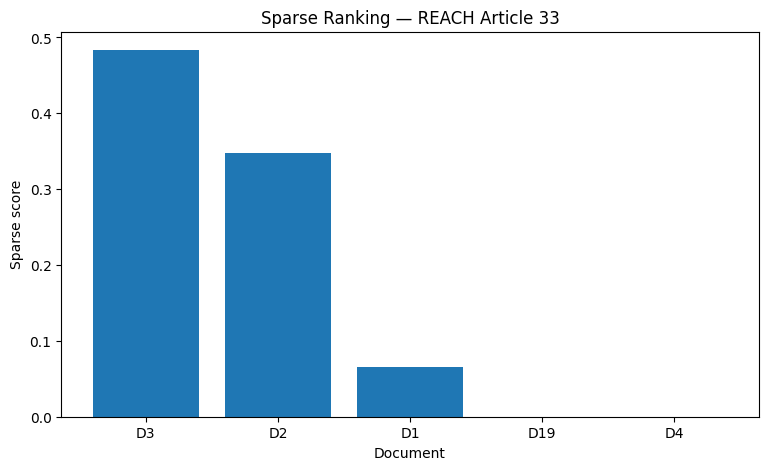

In [19]:
plt.figure(figsize=(9, 5))
plt.bar(
    sparse_article["id"],
    sparse_article["sparse_score"]
)
plt.xlabel("Document")
plt.ylabel("Sparse score")
plt.title("Sparse Ranking — REACH Article 33")
plt.show()

# 10. Exact-Match Strength

Lexical search is especially valuable for:

```text
E401
6ES7513-1AL02-0AB0
REACH Article 33
Regulation 2023/1542
Python 3.12
```

The important information is often the exact token itself.

In [20]:
print("ERROR CODE SEARCH")
sparse_search_verbose("E401", top_k=3)

print("\n\nPRODUCT CODE SEARCH")
sparse_search_verbose(
    "6ES7513-1AL02-0AB0",
    top_k=3
)

ERROR CODE SEARCH
SPARSE / LEXICAL SEARCH

STEP 1 — RAW QUERY
E401

STEP 2 — QUERY VECTOR SHAPE
(1, 326)

STEP 3 — NON-ZERO QUERY FEATURES
e401                           -> 1.0000

STEP 4 — SCORE FOR EVERY DOCUMENT
D1: 0.0000
D2: 0.0000
D3: 0.0000
D4: 0.0000
D5: 0.0000
D6: 0.2057
D7: 0.0000
D8: 0.0000
D9: 0.0000
D10: 0.0000
D11: 0.0000
D12: 0.0000
D13: 0.0000
D14: 0.0000
D15: 0.0000
D16: 0.0000
D17: 0.0000
D18: 0.0000
D19: 0.0000
D20: 0.0000

STEP 5 — COMPLETE RANKING
Rank  1: D6 score=0.2057
Rank  2: D20 score=0.0000
Rank  3: D19 score=0.0000
Rank  4: D2 score=0.0000
Rank  5: D3 score=0.0000
Rank  6: D4 score=0.0000
Rank  7: D5 score=0.0000
Rank  8: D7 score=0.0000
Rank  9: D8 score=0.0000
Rank 10: D9 score=0.0000
Rank 11: D10 score=0.0000
Rank 12: D11 score=0.0000
Rank 13: D12 score=0.0000
Rank 14: D13 score=0.0000
Rank 15: D14 score=0.0000
Rank 16: D15 score=0.0000
Rank 17: D16 score=0.0000
Rank 18: D17 score=0.0000
Rank 19: D18 score=0.0000
Rank 20: D1 score=0.0000

STEP 6 — FINAL 

,id,category,text,sparse_score
5,D6,support,Error code E401 indicates an authentication failure caused by invalid or expired credentials.,0.20569
19,D20,battery,Battery fire safety guidance describes thermal runaway and emergency response procedures.,0.00000
18,D19,battery,Producers shall finance the collection and treatment of waste batteries.,0.00000




PRODUCT CODE SEARCH
SPARSE / LEXICAL SEARCH

STEP 1 — RAW QUERY
6ES7513-1AL02-0AB0

STEP 2 — QUERY VECTOR SHAPE
(1, 326)

STEP 3 — NON-ZERO QUERY FEATURES
0ab0                           -> 0.4472
1al02                          -> 0.4472
1al02 0ab0                     -> 0.4472
6es7513                        -> 0.4472
6es7513 1al02                  -> 0.4472

STEP 4 — SCORE FOR EVERY DOCUMENT
D1: 0.0000
D2: 0.0000
D3: 0.0000
D4: 0.0000
D5: 0.0000
D6: 0.0000
D7: 0.0000
D8: 0.0000
D9: 0.5312
D10: 0.0000
D11: 0.0000
D12: 0.0000
D13: 0.0000
D14: 0.0000
D15: 0.0000
D16: 0.0000
D17: 0.0000
D18: 0.0000
D19: 0.0000
D20: 0.0000

STEP 5 — COMPLETE RANKING
Rank  1: D9 score=0.5312
Rank  2: D20 score=0.0000
Rank  3: D19 score=0.0000
Rank  4: D2 score=0.0000
Rank  5: D3 score=0.0000
Rank  6: D4 score=0.0000
Rank  7: D5 score=0.0000
Rank  8: D6 score=0.0000
Rank  9: D7 score=0.0000
Rank 10: D8 score=0.0000
Rank 11: D10 score=0.0000
Rank 12: D11 score=0.0000
Rank 13: D12 score=0.0000
Rank 14: D13 sc

,id,category,text,sparse_score
8,D9,product,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation CPU.,0.531197
19,D20,battery,Battery fire safety guidance describes thermal runaway and emergency response procedures.,0.000000
18,D19,battery,Producers shall finance the collection and treatment of waste batteries.,0.000000


,id,category,text,sparse_score
8,D9,product,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation CPU.,0.531197
19,D20,battery,Battery fire safety guidance describes thermal runaway and emergency response procedures.,0.000000
18,D19,battery,Producers shall finance the collection and treatment of waste batteries.,0.000000


# CHECKPOINT 1

You should now be able to explain:

1. What tokenization is.
2. Why tokenization can matter for product codes.
3. What vocabulary mismatch means.
4. Why lexical representations are sparse.
5. Why `E401` is an excellent lexical query.

# 11. Semantic / Dense Retrieval

Semantic search focuses on meaning.

For example:

```text
cannot log in
```

and:

```text
authentication failure
```

have different words but related meanings.

An embedding model converts text into a dense vector:

```text
"cannot log in"
→ [0.17, -0.44, 0.81, ...]

"authentication failure"
→ [0.19, -0.41, 0.79, ...]
```

Related meanings should ideally produce vectors that are close together.

## Why is it called dense?

A dense embedding may contain hundreds of numbers, and most are non-zero.

```text
[0.12, -0.08, 0.55, 0.21, ...]
```

Meaning is distributed across many dimensions.

In [21]:
from sentence_transformers import SentenceTransformer

print("Loading embedding model...")
print("Model: all-MiniLM-L6-v2")

embedding_model = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

print("Model loaded.")

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading embedding model...
Model: all-MiniLM-L6-v2


Loading weights: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 103/103 [00:00<00:00, 10785.50it/s]


Model loaded.


In [22]:
print("Encoding all documents...")

document_embeddings = embedding_model.encode(
    df["text"].tolist(),
    normalize_embeddings=True
)

print("\nEncoding complete.")
print("Documents:", document_embeddings.shape[0])
print("Dimensions:", document_embeddings.shape[1])
print("Matrix shape:", document_embeddings.shape)

Encoding all documents...

Encoding complete.
Documents: 20
Dimensions: 384
Matrix shape: (20, 384)


## 11.1 Inspect an Embedding

The numbers are not individually human-readable, but looking at them makes the concept concrete.

In [23]:
sample_embedding = document_embeddings[1]

print("DOCUMENT:")
print(df.iloc[1]["text"])

print("\nEMBEDDING SHAPE:")
print(sample_embedding.shape)

print("\nFIRST 20 VALUES:")
print(sample_embedding[:20])

print("\nMIN:", sample_embedding.min())
print("MAX:", sample_embedding.max())
print("MEAN:", sample_embedding.mean())

DOCUMENT:
REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.

EMBEDDING SHAPE:
(384,)

FIRST 20 VALUES:
[ 0.00021627  0.00184147 -0.05319398  0.0096258  -0.01528769 -0.0076818
 -0.02780571  0.07880239 -0.02220399 -0.06378564  0.00810809  0.00718271
 -0.03984725  0.02354954  0.00810093 -0.01361418  0.09372243 -0.00173711
 -0.02062134 -0.02118202]

MIN: -0.16704361
MAX: 0.17260055
MEAN: 0.00038276953


# 12. Cosine Similarity — From Zero

We need a mathematical way to compare vectors.

One common method is **cosine similarity**.

\[
\cos(\theta)=\frac{A \cdot B}{||A|| ||B||}
\]

Intuition:

```text
same direction      → high similarity
different direction → lower similarity
```

Because we normalize embeddings, their magnitudes are approximately 1.

So the dot product can be used as cosine similarity.

In [24]:
A = np.array([1.0, 2.0])
B = np.array([2.0, 4.0])

print("A:", A)
print("B:", B)

dot_product = np.dot(A, B)

norm_A = np.linalg.norm(A)
norm_B = np.linalg.norm(B)

cosine = dot_product / (norm_A * norm_B)

print("\nDOT PRODUCT:")
print(dot_product)

print("\n||A||:")
print(norm_A)

print("\n||B||:")
print(norm_B)

print("\nCOSINE SIMILARITY:")
print(cosine)

A: [1. 2.]
B: [2. 4.]

DOT PRODUCT:
10.0

||A||:
2.23606797749979

||B||:
4.47213595499958

COSINE SIMILARITY:
0.9999999999999998


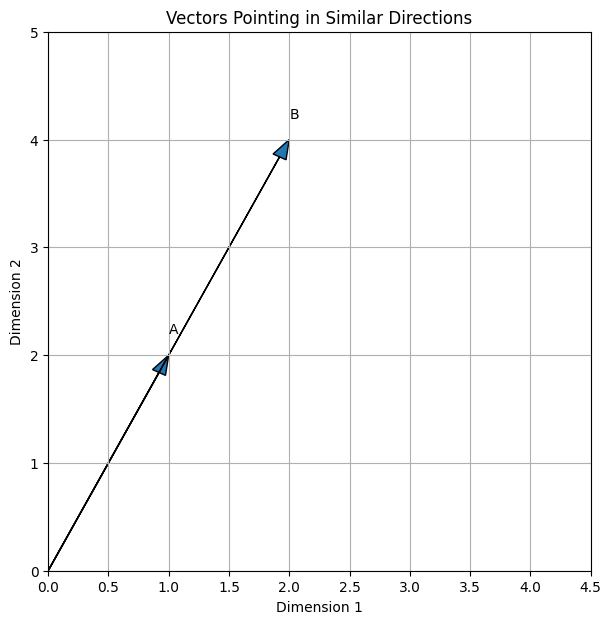

In [25]:
fig, ax = plt.subplots(figsize=(7, 7))

ax.arrow(
    0, 0, 1, 2,
    head_width=0.12,
    length_includes_head=True
)

ax.arrow(
    0, 0, 2, 4,
    head_width=0.12,
    length_includes_head=True
)

ax.text(1.0, 2.2, "A")
ax.text(2.0, 4.2, "B")

ax.set_xlim(0, 4.5)
ax.set_ylim(0, 5)
ax.set_xlabel("Dimension 1")
ax.set_ylabel("Dimension 2")
ax.set_title("Vectors Pointing in Similar Directions")
ax.grid(True)

plt.show()

# 13. Dense Search — Full Internal Flow

```text
Query
 ↓
Embedding model
 ↓
Query vector
 ↓
Similarity against every document
 ↓
Sort
 ↓
Top-K
```

In [26]:
def dense_search_verbose(query, top_k=5):
    print("=" * 90)
    print("DENSE / SEMANTIC SEARCH")
    print("=" * 90)

    print("\nSTEP 1 — RAW QUERY")
    print(query)

    query_embedding = embedding_model.encode(
        [query],
        normalize_embeddings=True
    )[0]

    print("\nSTEP 2 — QUERY EMBEDDING")
    print("Dimensions:", len(query_embedding))
    print("First 15 values:")
    print(query_embedding[:15])

    scores = document_embeddings @ query_embedding

    print("\nSTEP 3 — SCORE FOR EVERY DOCUMENT")

    for i, score in enumerate(scores):
        print(f"{df.iloc[i]['id']}: {score:.4f}")

    ranked_indices = np.argsort(scores)[::-1]

    print("\nSTEP 4 — COMPLETE RANKING")

    for rank, idx in enumerate(ranked_indices, start=1):
        print(
            f"Rank {rank:>2}: "
            f"{df.iloc[idx]['id']} "
            f"score={scores[idx]:.4f}"
        )

    top_indices = ranked_indices[:top_k]

    results = df.iloc[top_indices].copy()
    results["dense_score"] = scores[top_indices]

    print(f"\nSTEP 5 — FINAL TOP-{top_k}")

    display(
        results[
            ["id", "category", "text", "dense_score"]
        ]
    )

    return results[
        ["id", "category", "text", "dense_score"]
    ]

In [27]:
dense_login = dense_search_verbose(
    "Why can't a user log in?",
    top_k=5
)

DENSE / SEMANTIC SEARCH

STEP 1 — RAW QUERY
Why can't a user log in?

STEP 2 — QUERY EMBEDDING
Dimensions: 384
First 15 values:
[ 0.04968615 -0.02264963 -0.05171239 -0.06977119 -0.04852819 -0.03439729
  0.04162312  0.01326478  0.04710206  0.00620582  0.00557144  0.04757309
 -0.0188077   0.04217554  0.04327385]

STEP 3 — SCORE FOR EVERY DOCUMENT
D1: 0.0809
D2: -0.0370
D3: -0.0454
D4: 0.0355
D5: -0.0663
D6: 0.3047
D7: 0.5701
D8: 0.2196
D9: -0.0284
D10: -0.0559
D11: 0.1405
D12: 0.0921
D13: 0.0755
D14: 0.0561
D15: 0.0108
D16: 0.0205
D17: 0.0758
D18: 0.0808
D19: -0.0512
D20: 0.0583

STEP 4 — COMPLETE RANKING
Rank  1: D7 score=0.5701
Rank  2: D6 score=0.3047
Rank  3: D8 score=0.2196
Rank  4: D11 score=0.1405
Rank  5: D12 score=0.0921
Rank  6: D1 score=0.0809
Rank  7: D18 score=0.0808
Rank  8: D17 score=0.0758
Rank  9: D13 score=0.0755
Rank 10: D20 score=0.0583
Rank 11: D14 score=0.0561
Rank 12: D4 score=0.0355
Rank 13: D16 score=0.0205
Rank 14: D15 score=0.0108
Rank 15: D9 score=-0.0284
Rank

,id,category,text,dense_score
6,D7,support,Users who cannot sign in should verify their login credentials and reset the password if required.,0.570083
5,D6,support,Error code E401 indicates an authentication failure caused by invalid or expired credentials.,0.304692
7,D8,support,Error code E503 indicates that the service is temporarily unavailable.,0.219625
10,D11,policy,Employees may work remotely for two days each week.,0.140514
11,D12,policy,The work-from-home allowance permits eligible employees to perform their duties away from the office.,0.092115


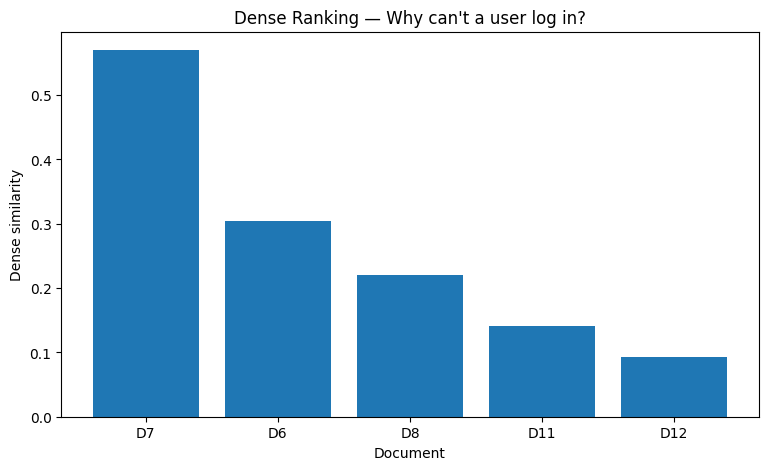

In [28]:
plt.figure(figsize=(9, 5))
plt.bar(
    dense_login["id"],
    dense_login["dense_score"]
)
plt.xlabel("Document")
plt.ylabel("Dense similarity")
plt.title("Dense Ranking — Why can't a user log in?")
plt.show()

# 14. Semantic Neighborhood

Dense embeddings try to place semantically related phrases near each other.

Expected relationships:

```text
work from home ≈ remote working
cannot log in ≈ authentication failure
battery recycling ≈ waste battery collection
```

In [29]:
phrases = [
    "work from home",
    "remote working",
    "cannot log in",
    "authentication failure",
    "battery recycling",
    "waste battery collection",
    "battery fire safety"
]

phrase_embeddings = embedding_model.encode(
    phrases,
    normalize_embeddings=True
)

similarity_matrix = (
    phrase_embeddings
    @ phrase_embeddings.T
)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=phrases,
    columns=phrases
)

display(
    similarity_df.round(3)
)

,work from home,remote working,cannot log in,authentication failure,battery recycling,waste battery collection,battery fire safety
work from home,1.000,0.364,0.064,0.082,0.057,0.063,0.057
remote working,0.364,1.000,0.202,0.224,0.054,0.062,0.083
cannot log in,0.064,0.202,1.000,0.672,0.036,-0.043,0.092
authentication failure,0.082,0.224,0.672,1.000,0.017,-0.040,0.107
battery recycling,0.057,0.054,0.036,0.017,1.000,0.810,0.459
waste battery collection,0.063,0.062,-0.043,-0.040,0.810,1.000,0.440
battery fire safety,0.057,0.083,0.092,0.107,0.459,0.440,1.000


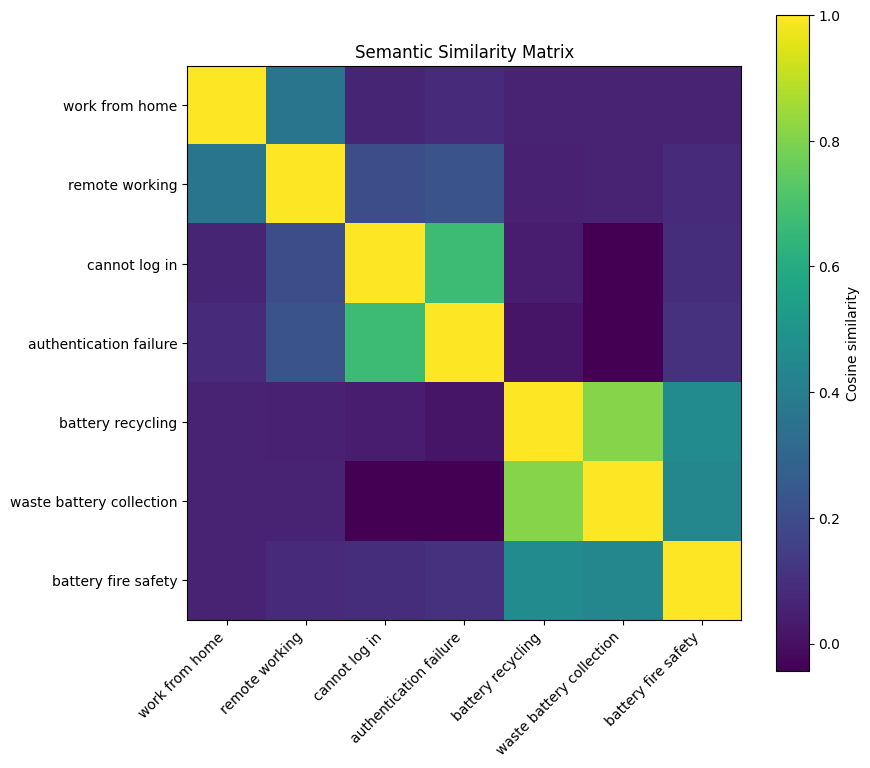

In [30]:
plt.figure(figsize=(9, 8))
plt.imshow(similarity_matrix)
plt.xticks(
    range(len(phrases)),
    phrases,
    rotation=45,
    ha="right"
)
plt.yticks(
    range(len(phrases)),
    phrases
)
plt.colorbar(label="Cosine similarity")
plt.title("Semantic Similarity Matrix")
plt.tight_layout()
plt.show()

# 15. Visualize Embeddings in 2D

Embeddings actually live in hundreds of dimensions.

We use PCA only to create a 2D visualization.

Important:

```text
The chart is an approximation.
Actual search uses the full-dimensional vectors.
```

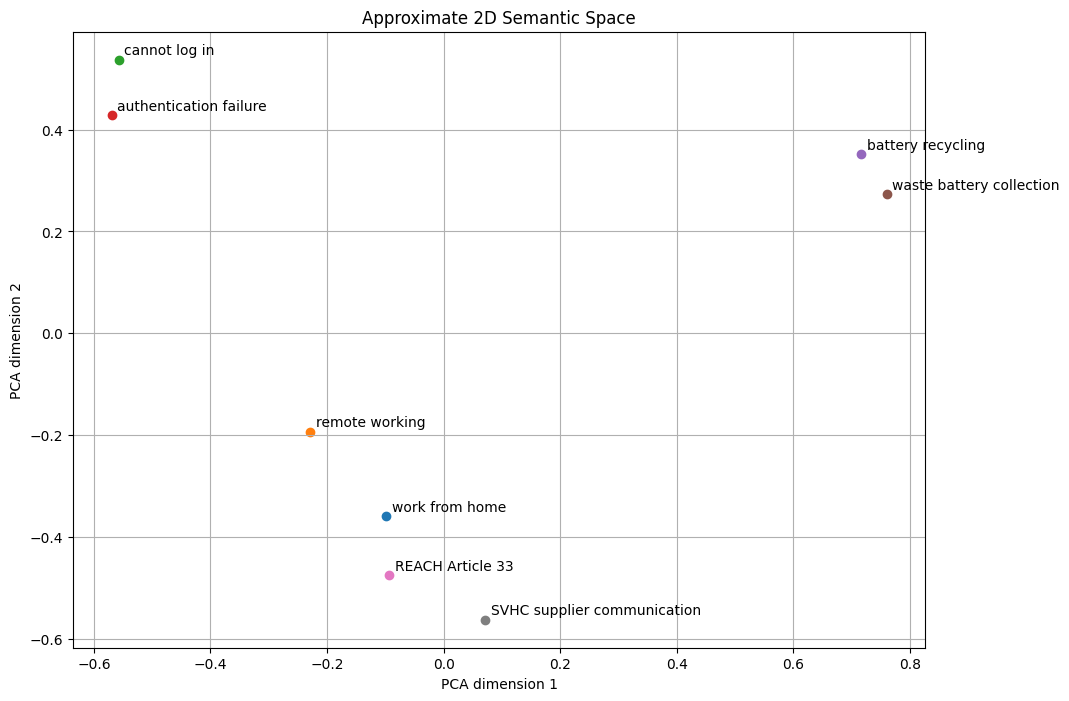

In [31]:
visual_texts = [
    "work from home",
    "remote working",
    "cannot log in",
    "authentication failure",
    "battery recycling",
    "waste battery collection",
    "REACH Article 33",
    "SVHC supplier communication"
]

visual_embeddings = embedding_model.encode(
    visual_texts,
    normalize_embeddings=True
)

pca = PCA(n_components=2)

points_2d = pca.fit_transform(
    visual_embeddings
)

plt.figure(figsize=(11, 8))

for i, text_item in enumerate(visual_texts):
    x, y = points_2d[i]
    plt.scatter(x, y)
    plt.text(
        x + 0.01,
        y + 0.01,
        text_item,
        fontsize=10
    )

plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.title("Approximate 2D Semantic Space")
plt.grid(True)
plt.show()

# CHECKPOINT 2

Explain these before continuing:

1. What is an embedding?
2. Why is the representation dense?
3. What does cosine similarity measure?
4. Why can `cannot log in` match `authentication failure`?
5. Why is the PCA plot only an approximation?

# 16. Compare Sparse and Dense Search Directly

Now both retrievers are ready.

We will run the same query through both.

In [32]:
def sparse_search(query, top_k=5):
    query_vector = tfidf_vectorizer.transform([query])

    scores = cosine_similarity(
        query_vector,
        tfidf_matrix
    ).flatten()

    ranked_indices = np.argsort(scores)[::-1][:top_k]

    results = df.iloc[ranked_indices].copy()
    results["sparse_score"] = scores[ranked_indices]

    return results[
        ["id", "category", "text", "sparse_score"]
    ]


def dense_search(query, top_k=5):
    query_embedding = embedding_model.encode(
        [query],
        normalize_embeddings=True
    )[0]

    scores = document_embeddings @ query_embedding

    ranked_indices = np.argsort(scores)[::-1][:top_k]

    results = df.iloc[ranked_indices].copy()
    results["dense_score"] = scores[ranked_indices]

    return results[
        ["id", "category", "text", "dense_score"]
    ]


def compare_sparse_dense(query, top_k=5):
    print("=" * 100)
    print("QUERY:", query)
    print("=" * 100)

    sparse = sparse_search(query, top_k)
    dense = dense_search(query, top_k)

    print("\nSPARSE RESULTS")
    display(sparse)

    print("\nDENSE RESULTS")
    display(dense)

    return sparse, dense

## 16.1 Exact Query

```text
E401
```

Prediction:

> Sparse retrieval should be very strong.

In [33]:
compare_sparse_dense(
    "E401",
    top_k=5
)

QUERY: E401

SPARSE RESULTS


,id,category,text,sparse_score
5,D6,support,Error code E401 indicates an authentication failure caused by invalid or expired credentials.,0.20569
19,D20,battery,Battery fire safety guidance describes thermal runaway and emergency response procedures.,0.00000
18,D19,battery,Producers shall finance the collection and treatment of waste batteries.,0.00000
1,D2,regulation,"REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.",0.00000
2,D3,regulation,REACH Article 34 contains separate information duties and is distinct from Article 33.,0.00000



DENSE RESULTS


,id,category,text,dense_score
5,D6,support,Error code E401 indicates an authentication failure caused by invalid or expired credentials.,0.541511
8,D9,product,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation CPU.,0.300994
7,D8,support,Error code E503 indicates that the service is temporarily unavailable.,0.259057
4,D5,regulation,Regulation EU 2025/40 establishes requirements for packaging and packaging waste.,0.197059
3,D4,regulation,Regulation EU 2023/1542 establishes requirements for batteries and waste batteries.,0.155063


(     id    category  \
 5    D6     support   
 19  D20     battery   
 18  D19     battery   
 1    D2  regulation   
 2    D3  regulation   
 
                                                                                                                             text  \
 5                                  Error code E401 indicates an authentication failure caused by invalid or expired credentials.   
 19                                     Battery fire safety guidance describes thermal runaway and emergency response procedures.   
 18                                                      Producers shall finance the collection and treatment of waste batteries.   
 1   REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.   
 2                                         REACH Article 34 contains separate information duties and is distinct from Article 33.   
 
     sparse_score  
 5        0.20569  
 19       0.00

## 16.2 Semantic Query

```text
Why can't users authenticate into the application?
```

Prediction:

> Dense retrieval should benefit from semantic similarity.

In [34]:
compare_sparse_dense(
    "Why can't users authenticate into the application?",
    top_k=5
)

QUERY: Why can't users authenticate into the application?

SPARSE RESULTS


,id,category,text,sparse_score
6,D7,support,Users who cannot sign in should verify their login credentials and reset the password if required.,0.228302
11,D12,policy,The work-from-home allowance permits eligible employees to perform their duties away from the office.,0.153256
18,D19,battery,Producers shall finance the collection and treatment of waste batteries.,0.104913
7,D8,support,Error code E503 indicates that the service is temporarily unavailable.,0.102840
19,D20,battery,Battery fire safety guidance describes thermal runaway and emergency response procedures.,0.000000



DENSE RESULTS


,id,category,text,dense_score
6,D7,support,Users who cannot sign in should verify their login credentials and reset the password if required.,0.508242
5,D6,support,Error code E401 indicates an authentication failure caused by invalid or expired credentials.,0.333712
7,D8,support,Error code E503 indicates that the service is temporarily unavailable.,0.141735
11,D12,policy,The work-from-home allowance permits eligible employees to perform their duties away from the office.,0.130239
0,D1,regulation,"REACH Regulation EC 1907/2006 governs registration, evaluation, authorisation and restriction of chemical substances.",0.122712


(     id category  \
 6    D7  support   
 11  D12   policy   
 18  D19  battery   
 7    D8  support   
 19  D20  battery   
 
                                                                                                      text  \
 6      Users who cannot sign in should verify their login credentials and reset the password if required.   
 11  The work-from-home allowance permits eligible employees to perform their duties away from the office.   
 18                               Producers shall finance the collection and treatment of waste batteries.   
 7                                  Error code E503 indicates that the service is temporarily unavailable.   
 19              Battery fire safety guidance describes thermal runaway and emergency response procedures.   
 
     sparse_score  
 6       0.228302  
 11      0.153256  
 18      0.104913  
 7       0.102840  
 19      0.000000  ,
      id    category  \
 6    D7     support   
 5    D6     support   
 7    D8     supp

## 16.3 Mixed Query

```text
What disclosure obligations apply under REACH Article 33?
```

This contains:

```text
Exact:
REACH
Article 33

Semantic:
disclosure obligations
```

This is the classic Hybrid Search case.

In [35]:
compare_sparse_dense(
    "What disclosure obligations apply under REACH Article 33?",
    top_k=5
)

QUERY: What disclosure obligations apply under REACH Article 33?

SPARSE RESULTS


,id,category,text,sparse_score
2,D3,regulation,REACH Article 34 contains separate information duties and is distinct from Article 33.,0.483320
1,D2,regulation,"REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.",0.348277
0,D1,regulation,"REACH Regulation EC 1907/2006 governs registration, evaluation, authorisation and restriction of chemical substances.",0.065368
18,D19,battery,Producers shall finance the collection and treatment of waste batteries.,0.000000
3,D4,regulation,Regulation EU 2023/1542 establishes requirements for batteries and waste batteries.,0.000000



DENSE RESULTS


,id,category,text,dense_score
2,D3,regulation,REACH Article 34 contains separate information duties and is distinct from Article 33.,0.714751
1,D2,regulation,"REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.",0.541625
0,D1,regulation,"REACH Regulation EC 1907/2006 governs registration, evaluation, authorisation and restriction of chemical substances.",0.344480
15,D16,retention,Records must be retained for 36 months.,0.337582
14,D15,retention,Records must be retained for 24 months.,0.292535


(     id    category  \
 2    D3  regulation   
 1    D2  regulation   
 0    D1  regulation   
 18  D19     battery   
 3    D4  regulation   
 
                                                                                                                             text  \
 2                                         REACH Article 34 contains separate information duties and is distinct from Article 33.   
 1   REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.   
 0          REACH Regulation EC 1907/2006 governs registration, evaluation, authorisation and restriction of chemical substances.   
 18                                                      Producers shall finance the collection and treatment of waste batteries.   
 3                                            Regulation EU 2023/1542 establishes requirements for batteries and waste batteries.   
 
     sparse_score  
 2       0.483320  
 1       0.348

# 17. Product IDs — Dense Search Weakness

A product ID such as:

```text
6ES7513-1AL02-0AB0
```

has little natural-language meaning.

The user normally wants:

```text
THIS exact item
```

not a conceptually related product.

In [36]:
compare_sparse_dense(
    "6ES7513-1AL02-0AB0",
    top_k=5
)

QUERY: 6ES7513-1AL02-0AB0

SPARSE RESULTS


,id,category,text,sparse_score
8,D9,product,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation CPU.,0.531197
19,D20,battery,Battery fire safety guidance describes thermal runaway and emergency response procedures.,0.000000
18,D19,battery,Producers shall finance the collection and treatment of waste batteries.,0.000000
1,D2,regulation,"REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.",0.000000
2,D3,regulation,REACH Article 34 contains separate information duties and is distinct from Article 33.,0.000000



DENSE RESULTS


,id,category,text,dense_score
8,D9,product,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation CPU.,0.536346
7,D8,support,Error code E503 indicates that the service is temporarily unavailable.,0.339123
5,D6,support,Error code E401 indicates an authentication failure caused by invalid or expired credentials.,0.271899
3,D4,regulation,Regulation EU 2023/1542 establishes requirements for batteries and waste batteries.,0.172309
12,D13,software,Python 3.12 installation troubleshooting includes dependency checks and environment configuration.,0.149312


(     id    category  \
 8    D9     product   
 19  D20     battery   
 18  D19     battery   
 1    D2  regulation   
 2    D3  regulation   
 
                                                                                                                             text  \
 8                                                            Siemens product 6ES7513-1AL02-0AB0 is an industrial automation CPU.   
 19                                     Battery fire safety guidance describes thermal runaway and emergency response procedures.   
 18                                                      Producers shall finance the collection and treatment of waste batteries.   
 1   REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.   
 2                                         REACH Article 34 contains separate information duties and is distinct from Article 33.   
 
     sparse_score  
 8       0.531197  
 19      0.000

# 18. Article Numbers

Compare:

```text
Article 33
Article 34
```

Their surrounding legal language may be similar.

But:

```text
33 ≠ 34
```

Exact numerical identity matters.

In [37]:
compare_sparse_dense(
    "REACH Article 33",
    top_k=5
)

QUERY: REACH Article 33

SPARSE RESULTS


,id,category,text,sparse_score
2,D3,regulation,REACH Article 34 contains separate information duties and is distinct from Article 33.,0.483320
1,D2,regulation,"REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.",0.348277
0,D1,regulation,"REACH Regulation EC 1907/2006 governs registration, evaluation, authorisation and restriction of chemical substances.",0.065368
18,D19,battery,Producers shall finance the collection and treatment of waste batteries.,0.000000
3,D4,regulation,Regulation EU 2023/1542 establishes requirements for batteries and waste batteries.,0.000000



DENSE RESULTS


,id,category,text,dense_score
2,D3,regulation,REACH Article 34 contains separate information duties and is distinct from Article 33.,0.734088
1,D2,regulation,"REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.",0.491156
0,D1,regulation,"REACH Regulation EC 1907/2006 governs registration, evaluation, authorisation and restriction of chemical substances.",0.278182
3,D4,regulation,Regulation EU 2023/1542 establishes requirements for batteries and waste batteries.,0.209159
4,D5,regulation,Regulation EU 2025/40 establishes requirements for packaging and packaging waste.,0.191919


(     id    category  \
 2    D3  regulation   
 1    D2  regulation   
 0    D1  regulation   
 18  D19     battery   
 3    D4  regulation   
 
                                                                                                                             text  \
 2                                         REACH Article 34 contains separate information duties and is distinct from Article 33.   
 1   REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.   
 0          REACH Regulation EC 1907/2006 governs registration, evaluation, authorisation and restriction of chemical substances.   
 18                                                      Producers shall finance the collection and treatment of waste batteries.   
 3                                            Regulation EU 2023/1542 establishes requirements for batteries and waste batteries.   
 
     sparse_score  
 2       0.483320  
 1       0.348

# 19. Version Numbers

Compare:

```text
Python 3.12
Python 3.11
```

The documentation can be nearly identical semantically.

But the version can determine whether instructions are correct.

In [38]:
compare_sparse_dense(
    "Python 3.12 installation troubleshooting",
    top_k=5
)

QUERY: Python 3.12 installation troubleshooting

SPARSE RESULTS


,id,category,text,sparse_score
12,D13,software,Python 3.12 installation troubleshooting includes dependency checks and environment configuration.,0.640828
13,D14,software,Python 3.11 installation troubleshooting includes dependency checks and environment configuration.,0.325184
19,D20,battery,Battery fire safety guidance describes thermal runaway and emergency response procedures.,0.000000
8,D9,product,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation CPU.,0.000000
1,D2,regulation,"REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.",0.000000



DENSE RESULTS


,id,category,text,dense_score
12,D13,software,Python 3.12 installation troubleshooting includes dependency checks and environment configuration.,0.877836
13,D14,software,Python 3.11 installation troubleshooting includes dependency checks and environment configuration.,0.781247
7,D8,support,Error code E503 indicates that the service is temporarily unavailable.,0.177248
5,D6,support,Error code E401 indicates an authentication failure caused by invalid or expired credentials.,0.063767
6,D7,support,Users who cannot sign in should verify their login credentials and reset the password if required.,0.053339


(     id    category  \
 12  D13    software   
 13  D14    software   
 19  D20     battery   
 8    D9     product   
 1    D2  regulation   
 
                                                                                                                             text  \
 12                            Python 3.12 installation troubleshooting includes dependency checks and environment configuration.   
 13                            Python 3.11 installation troubleshooting includes dependency checks and environment configuration.   
 19                                     Battery fire safety guidance describes thermal runaway and emergency response procedures.   
 8                                                            Siemens product 6ES7513-1AL02-0AB0 is an industrial automation CPU.   
 1   REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.   
 
     sparse_score  
 12      0.640828  
 13      0.325

# 20. Number Sensitivity

Compare:

```text
retain records for 24 months
retain records for 36 months
```

Most words are identical.

Only one number changes.

Yet the compliance obligation changes.

In [39]:
compare_sparse_dense(
    "records retained for 24 months",
    top_k=5
)

QUERY: records retained for 24 months

SPARSE RESULTS


,id,category,text,sparse_score
14,D15,retention,Records must be retained for 24 months.,0.792927
15,D16,retention,Records must be retained for 36 months.,0.429339
10,D11,policy,Employees may work remotely for two days each week.,0.044166
3,D4,regulation,Regulation EU 2023/1542 establishes requirements for batteries and waste batteries.,0.041286
4,D5,regulation,Regulation EU 2025/40 establishes requirements for packaging and packaging waste.,0.040061



DENSE RESULTS


,id,category,text,dense_score
14,D15,retention,Records must be retained for 24 months.,0.916665
15,D16,retention,Records must be retained for 36 months.,0.880806
2,D3,regulation,REACH Article 34 contains separate information duties and is distinct from Article 33.,0.080967
11,D12,policy,The work-from-home allowance permits eligible employees to perform their duties away from the office.,0.065970
10,D11,policy,Employees may work remotely for two days each week.,0.058999


(     id    category  \
 14  D15   retention   
 15  D16   retention   
 10  D11      policy   
 3    D4  regulation   
 4    D5  regulation   
 
                                                                                    text  \
 14                                              Records must be retained for 24 months.   
 15                                              Records must be retained for 36 months.   
 10                                  Employees may work remotely for two days each week.   
 3   Regulation EU 2023/1542 establishes requirements for batteries and waste batteries.   
 4     Regulation EU 2025/40 establishes requirements for packaging and packaging waste.   
 
     sparse_score  
 14      0.792927  
 15      0.429339  
 10      0.044166  
 3       0.041286  
 4       0.040061  ,
      id    category  \
 14  D15   retention   
 15  D16   retention   
 2    D3  regulation   
 11  D12      policy   
 10  D11      policy   
 
                                 

In [40]:
text_24 = "Records must be retained for 24 months."
text_36 = "Records must be retained for 36 months."

number_embeddings = embedding_model.encode(
    [text_24, text_36],
    normalize_embeddings=True
)

similarity = float(
    number_embeddings[0]
    @ number_embeddings[1]
)

print("TEXT A:")
print(text_24)

print("\nTEXT B:")
print(text_36)

print("\nDENSE SIMILARITY:")
print(round(similarity, 4))

print("\nInterpretation:")
print(
    "These sentences may remain very close semantically "
    "even though the number changes the factual requirement."
)

TEXT A:
Records must be retained for 24 months.

TEXT B:
Records must be retained for 36 months.

DENSE SIMILARITY:
0.9681

Interpretation:
These sentences may remain very close semantically even though the number changes the factual requirement.


# 21. Negation

Compare:

```text
Products containing substance X are prohibited.
```

with:

```text
Products containing substance X are not prohibited.
```

These statements are highly related topically.

But their meaning is opposite.

This demonstrates an important rule:

> Retrieval relevance is not the same as factual reasoning.

In [41]:
compare_sparse_dense(
    "Are products containing substance X prohibited?",
    top_k=5
)

QUERY: Are products containing substance X prohibited?

SPARSE RESULTS


,id,category,text,sparse_score
16,D17,compliance,Products containing substance X are prohibited.,0.864940
17,D18,compliance,Products containing substance X are not prohibited.,0.763261
9,D10,product,"Industrial automation controllers are selected based on processing capacity, communication interfaces and system requirements.",0.055037
8,D9,product,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation CPU.,0.000000
1,D2,regulation,"REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.",0.000000



DENSE RESULTS


,id,category,text,dense_score
16,D17,compliance,Products containing substance X are prohibited.,0.954726
17,D18,compliance,Products containing substance X are not prohibited.,0.903880
0,D1,regulation,"REACH Regulation EC 1907/2006 governs registration, evaluation, authorisation and restriction of chemical substances.",0.409700
4,D5,regulation,Regulation EU 2025/40 establishes requirements for packaging and packaging waste.,0.352290
1,D2,regulation,"REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.",0.312579


(     id    category  \
 16  D17  compliance   
 17  D18  compliance   
 9   D10     product   
 8    D9     product   
 1    D2  regulation   
 
                                                                                                                               text  \
 16                                                                                 Products containing substance X are prohibited.   
 17                                                                             Products containing substance X are not prohibited.   
 9   Industrial automation controllers are selected based on processing capacity, communication interfaces and system requirements.   
 8                                                              Siemens product 6ES7513-1AL02-0AB0 is an industrial automation CPU.   
 1     REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.   
 
     sparse_score  
 16      0.864940  
 1

In [42]:
negation_texts = [
    "Products containing substance X are prohibited.",
    "Products containing substance X are not prohibited."
]

negation_embeddings = embedding_model.encode(
    negation_texts,
    normalize_embeddings=True
)

negation_similarity = float(
    negation_embeddings[0]
    @ negation_embeddings[1]
)

print("STATEMENT A:")
print(negation_texts[0])

print("\nSTATEMENT B:")
print(negation_texts[1])

print("\nDENSE SIMILARITY:")
print(round(negation_similarity, 4))

STATEMENT A:
Products containing substance X are prohibited.

STATEMENT B:
Products containing substance X are not prohibited.

DENSE SIMILARITY:
0.9642


# 22. Acronyms and Domain Language

Enterprise corpora contain:

```text
SVHC
EPR
PFAS
WEEE
RoHS
MFA
WO
```

A pretrained embedding model may understand some acronyms well.

But internal or rare abbreviations may be poorly represented.

Lexical retrieval still preserves the exact string.

In [43]:
compare_sparse_dense(
    "SVHC supplier communication",
    top_k=5
)

QUERY: SVHC supplier communication

SPARSE RESULTS


,id,category,text,sparse_score
9,D10,product,"Industrial automation controllers are selected based on processing capacity, communication interfaces and system requirements.",0.200733
18,D19,battery,Producers shall finance the collection and treatment of waste batteries.,0.000000
1,D2,regulation,"REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.",0.000000
2,D3,regulation,REACH Article 34 contains separate information duties and is distinct from Article 33.,0.000000
3,D4,regulation,Regulation EU 2023/1542 establishes requirements for batteries and waste batteries.,0.000000



DENSE RESULTS


,id,category,text,dense_score
1,D2,regulation,"REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.",0.653594
8,D9,product,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation CPU.,0.234623
4,D5,regulation,Regulation EU 2025/40 establishes requirements for packaging and packaging waste.,0.222213
2,D3,regulation,REACH Article 34 contains separate information duties and is distinct from Article 33.,0.205769
18,D19,battery,Producers shall finance the collection and treatment of waste batteries.,0.181985


(     id    category  \
 9   D10     product   
 18  D19     battery   
 1    D2  regulation   
 2    D3  regulation   
 3    D4  regulation   
 
                                                                                                                               text  \
 9   Industrial automation controllers are selected based on processing capacity, communication interfaces and system requirements.   
 18                                                        Producers shall finance the collection and treatment of waste batteries.   
 1     REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.   
 2                                           REACH Article 34 contains separate information duties and is distinct from Article 33.   
 3                                              Regulation EU 2023/1542 establishes requirements for batteries and waste batteries.   
 
     sparse_score  
 9       0.200733  
 1

# 23. Three Practical Query Types

### Type A — Exact

```text
E401
6ES7513-1AL02-0AB0
REACH Article 33
```

Usually sparse-heavy.

### Type B — Semantic

```text
Why can't users sign in?
What is the remote-work policy?
```

Usually dense-heavy.

### Type C — Mixed

```text
What does REACH Article 33 require suppliers to disclose?
```

Usually Hybrid Search.

In [44]:
query_types = pd.DataFrame([
    {
        "type": "Exact",
        "query": "E401",
        "likely_strength": "Sparse / exact"
    },
    {
        "type": "Exact",
        "query": "6ES7513-1AL02-0AB0",
        "likely_strength": "Sparse / exact"
    },
    {
        "type": "Semantic",
        "query": "Why can't users sign in?",
        "likely_strength": "Dense"
    },
    {
        "type": "Semantic",
        "query": "What is the remote-work policy?",
        "likely_strength": "Dense"
    },
    {
        "type": "Mixed",
        "query": "What does REACH Article 33 require?",
        "likely_strength": "Hybrid"
    }
])

display(query_types)

,type,query,likely_strength
0,Exact,E401,Sparse / exact
1,Exact,6ES7513-1AL02-0AB0,Sparse / exact
2,Semantic,Why can't users sign in?,Dense
3,Semantic,What is the remote-work policy?,Dense
4,Mixed,What does REACH Article 33 require?,Hybrid


# 24. Visualize Sparse vs Dense Score Distributions

Let's use one semantic query.

Remember:

> Sparse and dense scores are not guaranteed to use the same numerical scale.

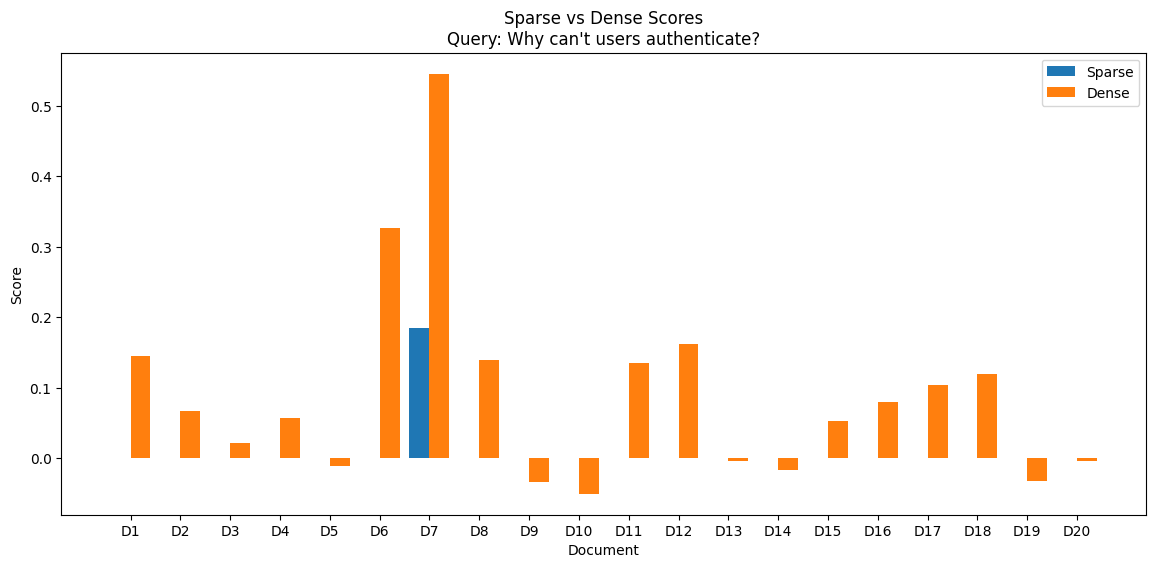

In [45]:
query = "Why can't users authenticate?"

sparse_query = tfidf_vectorizer.transform([query])

all_sparse_scores = cosine_similarity(
    sparse_query,
    tfidf_matrix
).flatten()

dense_query = embedding_model.encode(
    [query],
    normalize_embeddings=True
)[0]

all_dense_scores = (
    document_embeddings
    @ dense_query
)

x = np.arange(len(df))
width = 0.4

plt.figure(figsize=(14, 6))

plt.bar(
    x - width / 2,
    all_sparse_scores,
    width=width,
    label="Sparse"
)

plt.bar(
    x + width / 2,
    all_dense_scores,
    width=width,
    label="Dense"
)

plt.xticks(x, df["id"])
plt.xlabel("Document")
plt.ylabel("Score")
plt.title(
    "Sparse vs Dense Scores\n"
    f"Query: {query}"
)
plt.legend()
plt.show()

# 25. Hybrid Search — Combine Both Signals

A simple educational fusion formula is:

\[
HybridScore =
(1-\alpha)\times SparseNormalized
+
\alpha\times DenseNormalized
\]

Where:

```text
alpha = 0.0 → sparse only
alpha = 0.5 → balanced
alpha = 1.0 → dense only
```

## Why normalize?

Raw sparse and dense scores may use different ranges.

We first convert them to a comparable 0–1 range.

In [46]:
def min_max_normalize(values):
    values = np.asarray(
        values,
        dtype=float
    )

    minimum = values.min()
    maximum = values.max()

    print("Minimum:", minimum)
    print("Maximum:", maximum)

    if maximum == minimum:
        print("All scores identical.")
        return np.zeros_like(values)

    normalized = (
        (values - minimum)
        /
        (maximum - minimum)
    )

    return normalized


demo_scores = np.array(
    [2.0, 5.0, 10.0]
)

print("RAW:")
print(demo_scores)

print("\nNORMALIZATION:")
demo_normalized = min_max_normalize(
    demo_scores
)

print("\nRESULT:")
print(demo_normalized)

RAW:
[ 2.  5. 10.]

NORMALIZATION:
Minimum: 2.0
Maximum: 10.0

RESULT:
[0.    0.375 1.   ]


## 25.1 Hybrid Search With Full Internal Prints

In [47]:
def hybrid_search_verbose(query, top_k=5, alpha=0.5):
    print("=" * 110)
    print("HYBRID SEARCH")
    print("=" * 110)

    print("\nQUERY:")
    print(query)

    print("\nALPHA:", alpha)
    print("Dense weight:", alpha)
    print("Sparse weight:", 1 - alpha)

    # Sparse
    sparse_query = tfidf_vectorizer.transform([query])

    sparse_scores = cosine_similarity(
        sparse_query,
        tfidf_matrix
    ).flatten()

    # Dense
    dense_query = embedding_model.encode(
        [query],
        normalize_embeddings=True
    )[0]

    dense_scores = (
        document_embeddings
        @ dense_query
    )

    print("\nNORMALIZING SPARSE SCORES")
    sparse_norm = min_max_normalize(
        sparse_scores
    )

    print("\nNORMALIZING DENSE SCORES")
    dense_norm = min_max_normalize(
        dense_scores
    )

    hybrid_scores = (
        (1 - alpha) * sparse_norm
        +
        alpha * dense_norm
    )

    print("\nPER-DOCUMENT SCORE FLOW")

    for i in range(len(df)):
        print(
            f"{df.iloc[i]['id']}: "
            f"sparse_raw={sparse_scores[i]:.4f} | "
            f"dense_raw={dense_scores[i]:.4f} | "
            f"sparse_norm={sparse_norm[i]:.4f} | "
            f"dense_norm={dense_norm[i]:.4f} | "
            f"hybrid={hybrid_scores[i]:.4f}"
        )

    ranked_indices = np.argsort(
        hybrid_scores
    )[::-1]

    print("\nFINAL RANKING")

    for rank, idx in enumerate(
        ranked_indices,
        start=1
    ):
        print(
            f"Rank {rank:>2}: "
            f"{df.iloc[idx]['id']} "
            f"hybrid={hybrid_scores[idx]:.4f}"
        )

    top_indices = ranked_indices[:top_k]

    results = df.iloc[top_indices].copy()

    results["sparse_raw"] = sparse_scores[top_indices]
    results["dense_raw"] = dense_scores[top_indices]
    results["sparse_norm"] = sparse_norm[top_indices]
    results["dense_norm"] = dense_norm[top_indices]
    results["hybrid_score"] = hybrid_scores[top_indices]

    print(f"\nTOP-{top_k}")
    display(results)

    return results

In [48]:
hybrid_results = hybrid_search_verbose(
    "What disclosure obligations apply under REACH Article 33 for SVHCs?",
    top_k=5,
    alpha=0.5
)

HYBRID SEARCH

QUERY:
What disclosure obligations apply under REACH Article 33 for SVHCs?

ALPHA: 0.5
Dense weight: 0.5
Sparse weight: 0.5

NORMALIZING SPARSE SCORES
Minimum: 0.0
Maximum: 0.40990233940108

NORMALIZING DENSE SCORES
Minimum: -0.008483953773975372
Maximum: 0.7669726610183716

PER-DOCUMENT SCORE FLOW
D1: sparse_raw=0.0554 | dense_raw=0.3400 | sparse_norm=0.1352 | dense_norm=0.4494 | hybrid=0.2923
D2: sparse_raw=0.3748 | dense_raw=0.7670 | sparse_norm=0.9143 | dense_norm=1.0000 | hybrid=0.9572
D3: sparse_raw=0.4099 | dense_raw=0.6164 | sparse_norm=1.0000 | dense_norm=0.8059 | hybrid=0.9029
D4: sparse_raw=0.0464 | dense_raw=0.2378 | sparse_norm=0.1133 | dense_norm=0.3175 | hybrid=0.2154
D5: sparse_raw=0.0451 | dense_raw=0.2836 | sparse_norm=0.1099 | dense_norm=0.3766 | hybrid=0.2433
D6: sparse_raw=0.0000 | dense_raw=0.0775 | sparse_norm=0.0000 | dense_norm=0.1109 | hybrid=0.0555
D7: sparse_raw=0.0000 | dense_raw=0.0113 | sparse_norm=0.0000 | dense_norm=0.0255 | hybrid=0.0127

,id,category,text,sparse_raw,dense_raw,sparse_norm,dense_norm,hybrid_score
1,D2,regulation,"REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.",0.374778,0.766973,0.914311,1.000000,0.957155
2,D3,regulation,REACH Article 34 contains separate information duties and is distinct from Article 33.,0.409902,0.616439,1.000000,0.805877,0.902939
0,D1,regulation,"REACH Regulation EC 1907/2006 governs registration, evaluation, authorisation and restriction of chemical substances.",0.055439,0.340015,0.135248,0.449412,0.292330
15,D16,retention,Records must be retained for 36 months.,0.061593,0.297296,0.150263,0.394322,0.272292
14,D15,retention,Records must be retained for 24 months.,0.061593,0.260243,0.150263,0.346541,0.248402


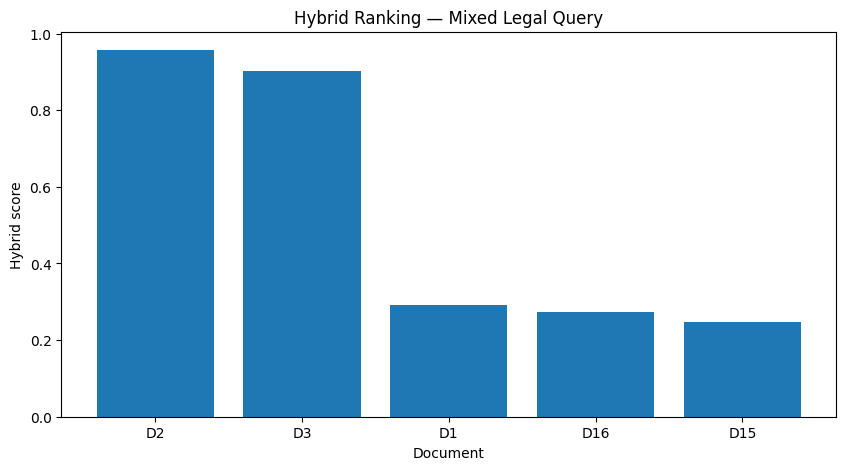

In [49]:
plt.figure(figsize=(10, 5))
plt.bar(
    hybrid_results["id"],
    hybrid_results["hybrid_score"]
)
plt.xlabel("Document")
plt.ylabel("Hybrid score")
plt.title("Hybrid Ranking — Mixed Legal Query")
plt.show()

# 26. Alpha as a Dial

```text
alpha = 0.0
Sparse only

alpha = 0.2
Sparse-heavy

alpha = 0.5
Balanced

alpha = 0.8
Dense-heavy

alpha = 1.0
Dense only
```

There is no universal best alpha.

You should tune it using real evaluation queries.

In [50]:
def hybrid_search(query, top_k=5, alpha=0.5):
    sparse_query = tfidf_vectorizer.transform([query])

    sparse_scores = cosine_similarity(
        sparse_query,
        tfidf_matrix
    ).flatten()

    dense_query = embedding_model.encode(
        [query],
        normalize_embeddings=True
    )[0]

    dense_scores = (
        document_embeddings
        @ dense_query
    )

    sparse_norm = (
        (sparse_scores - sparse_scores.min())
        /
        (sparse_scores.max() - sparse_scores.min() + 1e-12)
    )

    dense_norm = (
        (dense_scores - dense_scores.min())
        /
        (dense_scores.max() - dense_scores.min() + 1e-12)
    )

    hybrid_scores = (
        (1 - alpha) * sparse_norm
        +
        alpha * dense_norm
    )

    ranked_indices = np.argsort(
        hybrid_scores
    )[::-1][:top_k]

    results = df.iloc[ranked_indices].copy()
    results["hybrid_score"] = hybrid_scores[ranked_indices]

    return results[
        ["id", "category", "text", "hybrid_score"]
    ]

In [51]:
query = (
    "What obligations apply under "
    "Regulation 2023/1542 for battery waste?"
)

rows = []

for alpha in [0.0, 0.2, 0.5, 0.8, 1.0]:
    result = hybrid_search(
        query,
        top_k=1,
        alpha=alpha
    )

    rows.append({
        "alpha": alpha,
        "top_document": result.iloc[0]["id"],
        "top_score": result.iloc[0]["hybrid_score"]
    })

alpha_summary = pd.DataFrame(rows)

display(alpha_summary)

,alpha,top_document,top_score
0,0.0,D4,1.0
1,0.2,D4,1.0
2,0.5,D4,1.0
3,0.8,D4,1.0
4,1.0,D4,1.0


# 27. Dynamic Weighting — Advanced Preview

A production system may adapt retrieval based on query type.

```text
E401
→ sparse-heavy

Why can't users log in?
→ dense-heavy

What does REACH Article 33 require?
→ balanced / hybrid
```

We implement a simple heuristic only to understand the idea.

In [52]:
def detect_query_type(query):
    contains_article = bool(
        re.search(
            r"\barticle\s+\d+",
            query,
            flags=re.IGNORECASE
        )
    )

    contains_error = bool(
        re.search(
            r"\bE\d{3,}\b",
            query,
            flags=re.IGNORECASE
        )
    )

    contains_code = bool(
        re.search(
            r"[A-Za-z0-9]+[-_/][A-Za-z0-9\-_/]+",
            query
        )
    )

    word_count = len(
        query.split()
    )

    print("Query:", query)
    print("contains_article:", contains_article)
    print("contains_error:", contains_error)
    print("contains_code:", contains_code)
    print("word_count:", word_count)

    has_exact_signal = (
        contains_article
        or contains_error
        or contains_code
    )

    if has_exact_signal and word_count <= 5:
        return "exact"

    if has_exact_signal and word_count > 5:
        return "mixed"

    if word_count >= 6:
        return "semantic"

    return "mixed"


def choose_alpha(query):
    query_type = detect_query_type(query)

    if query_type == "exact":
        alpha = 0.2
    elif query_type == "semantic":
        alpha = 0.8
    else:
        alpha = 0.5

    print("\nDetected:", query_type)
    print("Chosen alpha:", alpha)

    return alpha

In [53]:
test_queries = [
    "E401",
    "REACH Article 33",
    "Why can't users authenticate into the application?",
    "What does REACH Article 33 require suppliers to disclose?"
]

for query in test_queries:
    print("\n" + "=" * 100)
    choose_alpha(query)


Query: E401
contains_article: False
contains_error: True
contains_code: False
word_count: 1

Detected: exact
Chosen alpha: 0.2

Query: REACH Article 33
contains_article: True
contains_error: False
contains_code: False
word_count: 3

Detected: exact
Chosen alpha: 0.2

Query: Why can't users authenticate into the application?
contains_article: False
contains_error: False
contains_code: False
word_count: 7

Detected: semantic
Chosen alpha: 0.8

Query: What does REACH Article 33 require suppliers to disclose?
contains_article: True
contains_error: False
contains_code: False
word_count: 9

Detected: mixed
Chosen alpha: 0.5


This heuristic is **not production-grade**.

A production system might use:

- deterministic ID detection
- query classifiers
- metadata
- RRF
- learned ranking
- offline evaluation

# 28. Retrieval Evaluation

Do not rely on:

```text
"This looks better."
```

Use labeled queries.

We will begin with **Hit@K**.

### Hit@K

If at least one relevant document appears in Top-K:

```text
Hit@K = 1
```

Otherwise:

```text
Hit@K = 0
```

In [54]:
evaluation_queries = [
    {
        "query": "E401",
        "expected_ids": {"D6"}
    },
    {
        "query": "What is the work from home policy?",
        "expected_ids": {"D11", "D12"}
    },
    {
        "query": "REACH Article 33",
        "expected_ids": {"D2"}
    },
    {
        "query": "Python 3.12 installation problem",
        "expected_ids": {"D13"}
    },
    {
        "query": "Who pays for collecting discarded batteries?",
        "expected_ids": {"D19"}
    },
    {
        "query": "records retained for 24 months",
        "expected_ids": {"D15"}
    }
]

print(
    "Evaluation queries:",
    len(evaluation_queries)
)

Evaluation queries: 6


In [55]:
def evaluate_method(
    search_function,
    method_name,
    top_k=3
):
    rows = []

    print("=" * 100)
    print("METHOD:", method_name)
    print("=" * 100)

    for item in evaluation_queries:
        query = item["query"]
        expected = item["expected_ids"]

        results = search_function(
            query,
            top_k=top_k
        )

        retrieved = results["id"].tolist()

        overlap = (
            set(retrieved)
            .intersection(expected)
        )

        hit = int(
            len(overlap) > 0
        )

        print("\nQUERY:")
        print(query)

        print("Expected:")
        print(expected)

        print("Retrieved:")
        print(retrieved)

        print("Relevant found:")
        print(overlap)

        print(f"Hit@{top_k}: {hit}")

        rows.append({
            "method": method_name,
            "query": query,
            "retrieved": retrieved,
            f"hit@{top_k}": hit
        })

    return pd.DataFrame(rows)

In [56]:
sparse_eval = evaluate_method(
    sparse_search,
    "Sparse",
    top_k=3
)

dense_eval = evaluate_method(
    dense_search,
    "Dense",
    top_k=3
)

hybrid_eval = evaluate_method(
    lambda q, top_k: hybrid_search(
        q,
        top_k=top_k,
        alpha=0.5
    ),
    "Hybrid",
    top_k=3
)

evaluation_table = pd.concat(
    [
        sparse_eval,
        dense_eval,
        hybrid_eval
    ],
    ignore_index=True
)

display(evaluation_table)

METHOD: Sparse

QUERY:
E401
Expected:
{'D6'}
Retrieved:
['D6', 'D20', 'D19']
Relevant found:
{'D6'}
Hit@3: 1

QUERY:
What is the work from home policy?
Expected:
{'D11', 'D12'}
Retrieved:
['D12', 'D3', 'D8']
Relevant found:
{'D12'}
Hit@3: 1

QUERY:
REACH Article 33
Expected:
{'D2'}
Retrieved:
['D3', 'D2', 'D1']
Relevant found:
{'D2'}
Hit@3: 1

QUERY:
Python 3.12 installation problem
Expected:
{'D13'}
Retrieved:
['D13', 'D14', 'D20']
Relevant found:
{'D13'}
Hit@3: 1

QUERY:
Who pays for collecting discarded batteries?
Expected:
{'D19'}
Retrieved:
['D4', 'D19', 'D7']
Relevant found:
{'D19'}
Hit@3: 1

QUERY:
records retained for 24 months
Expected:
{'D15'}
Retrieved:
['D15', 'D16', 'D11']
Relevant found:
{'D15'}
Hit@3: 1
METHOD: Dense

QUERY:
E401
Expected:
{'D6'}
Retrieved:
['D6', 'D9', 'D8']
Relevant found:
{'D6'}
Hit@3: 1

QUERY:
What is the work from home policy?
Expected:
{'D11', 'D12'}
Retrieved:
['D12', 'D11', 'D5']
Relevant found:
{'D11', 'D12'}
Hit@3: 1

QUERY:
REACH Article 33
E

,method,query,retrieved,hit@3
0,Sparse,E401,"[D6, D20, D19]",1
1,Sparse,What is the work from home policy?,"[D12, D3, D8]",1
2,Sparse,REACH Article 33,"[D3, D2, D1]",1
3,Sparse,Python 3.12 installation problem,"[D13, D14, D20]",1
4,Sparse,Who pays for collecting discarded batteries?,"[D4, D19, D7]",1
5,Sparse,records retained for 24 months,"[D15, D16, D11]",1
6,Dense,E401,"[D6, D9, D8]",1
7,Dense,What is the work from home policy?,"[D12, D11, D5]",1
8,Dense,REACH Article 33,"[D3, D2, D1]",1
9,Dense,Python 3.12 installation problem,"[D13, D14, D8]",1


AVERAGE HIT@3


method
Dense     1.0
Hybrid    1.0
Sparse    1.0
Name: hit@3, dtype: float64

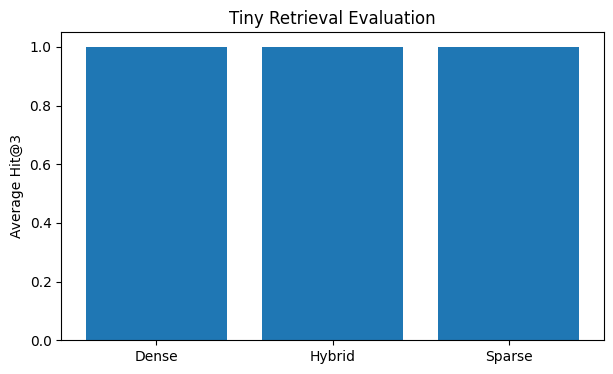

In [57]:
metric = "hit@3"

aggregate = (
    evaluation_table
    .groupby("method")[metric]
    .mean()
    .sort_values(ascending=False)
)

print("AVERAGE HIT@3")
display(aggregate)

plt.figure(figsize=(7, 4))
plt.bar(
    aggregate.index,
    aggregate.values
)
plt.ylim(0, 1.05)
plt.ylabel("Average Hit@3")
plt.title("Tiny Retrieval Evaluation")
plt.show()

The dataset above is intentionally tiny.

For production work, use many representative queries and human relevance labels.

# 29. Retrieval Debugging Framework

When a RAG answer is wrong:

```text
1. Does the correct document exist?
2. Did sparse retrieval find it?
3. Did dense retrieval find it?
4. Did fusion keep it?
5. Did reranking remove it?
6. Did the evidence reach the LLM?
7. Did the LLM misinterpret it?
```

This helps you avoid incorrectly blaming the LLM.

In [58]:
def debug_retrieval(
    query,
    top_k=5,
    alpha=0.5
):
    print("=" * 110)
    print("RETRIEVAL DEBUG REPORT")
    print("=" * 110)

    print("\nQUERY:")
    print(query)

    sparse = sparse_search(
        query,
        top_k
    )

    dense = dense_search(
        query,
        top_k
    )

    hybrid = hybrid_search(
        query,
        top_k=top_k,
        alpha=alpha
    )

    print("\nSPARSE")
    display(sparse)

    print("\nDENSE")
    display(dense)

    print("\nHYBRID")
    display(hybrid)

    sparse_ids = set(
        sparse["id"].tolist()
    )

    dense_ids = set(
        dense["id"].tolist()
    )

    hybrid_ids = set(
        hybrid["id"].tolist()
    )

    print("\nOVERLAP")
    print(
        "Sparse ∩ Dense:",
        sparse_ids.intersection(dense_ids)
    )

    print(
        "Sparse ∩ Hybrid:",
        sparse_ids.intersection(hybrid_ids)
    )

    print(
        "Dense ∩ Hybrid:",
        dense_ids.intersection(hybrid_ids)
    )

    return {
        "sparse": sparse,
        "dense": dense,
        "hybrid": hybrid
    }

In [59]:
debug_retrieval(
    "Python 3.12 installation troubleshooting",
    top_k=5,
    alpha=0.5
)

RETRIEVAL DEBUG REPORT

QUERY:
Python 3.12 installation troubleshooting

SPARSE


,id,category,text,sparse_score
12,D13,software,Python 3.12 installation troubleshooting includes dependency checks and environment configuration.,0.640828
13,D14,software,Python 3.11 installation troubleshooting includes dependency checks and environment configuration.,0.325184
19,D20,battery,Battery fire safety guidance describes thermal runaway and emergency response procedures.,0.000000
8,D9,product,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation CPU.,0.000000
1,D2,regulation,"REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.",0.000000



DENSE


,id,category,text,dense_score
12,D13,software,Python 3.12 installation troubleshooting includes dependency checks and environment configuration.,0.877836
13,D14,software,Python 3.11 installation troubleshooting includes dependency checks and environment configuration.,0.781247
7,D8,support,Error code E503 indicates that the service is temporarily unavailable.,0.177248
5,D6,support,Error code E401 indicates an authentication failure caused by invalid or expired credentials.,0.063767
6,D7,support,Users who cannot sign in should verify their login credentials and reset the password if required.,0.053339



HYBRID


,id,category,text,hybrid_score
12,D13,software,Python 3.12 installation troubleshooting includes dependency checks and environment configuration.,1.000000
13,D14,software,Python 3.11 installation troubleshooting includes dependency checks and environment configuration.,0.704352
7,D8,support,Error code E503 indicates that the service is temporarily unavailable.,0.141911
5,D6,support,Error code E401 indicates an authentication failure caused by invalid or expired credentials.,0.083909
6,D7,support,Users who cannot sign in should verify their login credentials and reset the password if required.,0.078578



OVERLAP
Sparse ∩ Dense: {'D14', 'D13'}
Sparse ∩ Hybrid: {'D14', 'D13'}
Dense ∩ Hybrid: {'D7', 'D14', 'D6', 'D13', 'D8'}


{'sparse':      id    category  \
 12  D13    software   
 13  D14    software   
 19  D20     battery   
 8    D9     product   
 1    D2  regulation   
 
                                                                                                                             text  \
 12                            Python 3.12 installation troubleshooting includes dependency checks and environment configuration.   
 13                            Python 3.11 installation troubleshooting includes dependency checks and environment configuration.   
 19                                     Battery fire safety guidance describes thermal runaway and emergency response procedures.   
 8                                                            Siemens product 6ES7513-1AL02-0AB0 is an industrial automation CPU.   
 1   REACH Article 33 requires suppliers to communicate information about substances of very high concern, commonly called SVHCs.   
 
     sparse_score  
 12      0.640828  
 13 

# 30. Production Mental Model

Real ranking may use more than sparse and dense relevance.

Conceptually:

\[
Relevance =
f(
Lexical,
Semantic,
Metadata,
Freshness,
Authority,
BusinessRules
)
\]

Example:

```text
Query
 ├── BM25 signal
 ├── embedding signal
 ├── country filter
 ├── date filter
 ├── source authority
 └── access rules
       ↓
   candidates
```

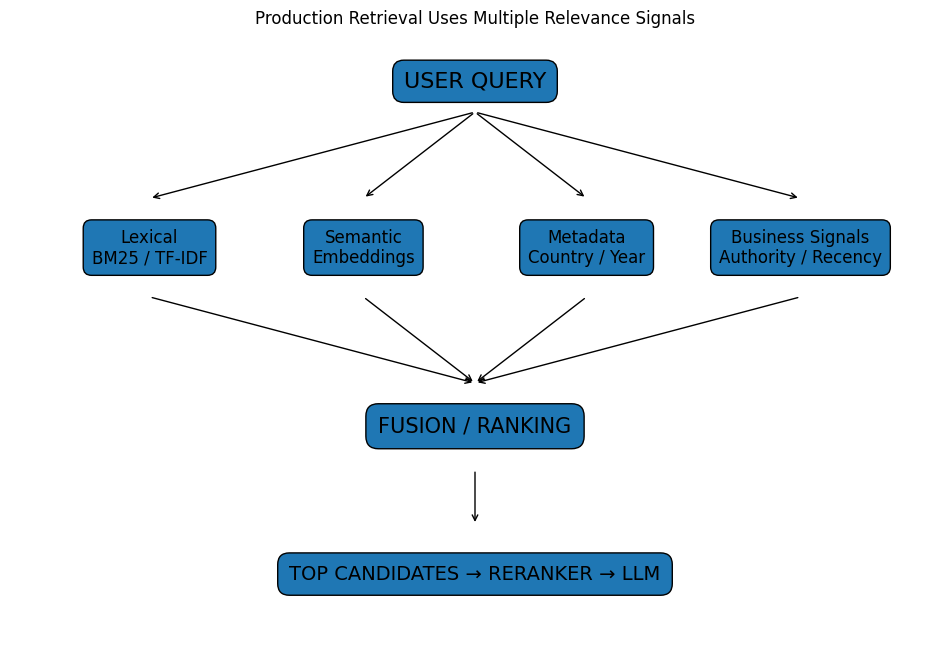

In [60]:
fig, ax = plt.subplots(figsize=(12, 8))
ax.axis("off")

ax.text(
    0.5, 0.92,
    "USER QUERY",
    ha="center", va="center", fontsize=16,
    bbox=dict(boxstyle="round,pad=0.5")
)

signals = [
    (0.15, "Lexical\nBM25 / TF-IDF"),
    (0.38, "Semantic\nEmbeddings"),
    (0.62, "Metadata\nCountry / Year"),
    (0.85, "Business Signals\nAuthority / Recency")
]

for x, label in signals:
    ax.text(
        x, 0.65,
        label,
        ha="center", va="center", fontsize=12,
        bbox=dict(boxstyle="round,pad=0.5")
    )

    ax.annotate(
        "",
        xy=(x, 0.73),
        xytext=(0.5, 0.87),
        arrowprops=dict(arrowstyle="->")
    )

ax.text(
    0.5, 0.36,
    "FUSION / RANKING",
    ha="center", va="center", fontsize=15,
    bbox=dict(boxstyle="round,pad=0.6")
)

for x, _ in signals:
    ax.annotate(
        "",
        xy=(0.5, 0.43),
        xytext=(x, 0.57),
        arrowprops=dict(arrowstyle="->")
    )

ax.text(
    0.5, 0.12,
    "TOP CANDIDATES → RERANKER → LLM",
    ha="center", va="center", fontsize=14,
    bbox=dict(boxstyle="round,pad=0.6")
)

ax.annotate(
    "",
    xy=(0.5, 0.20),
    xytext=(0.5, 0.29),
    arrowprops=dict(arrowstyle="->")
)

plt.title(
    "Production Retrieval Uses Multiple Relevance Signals"
)
plt.show()

# 31. Retrieval Is Not Reasoning

Retriever:

```text
Find related evidence.
```

Reranker:

```text
Judge candidate relevance more carefully.
```

LLM / business logic:

```text
Interpret evidence and answer.
```

This distinction is critical for legal, regulatory, medical and technical RAG.

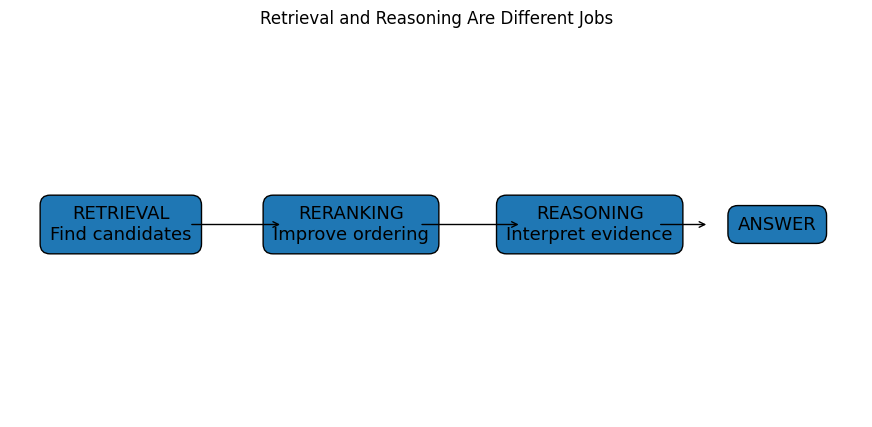

In [61]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.axis("off")

steps = [
    (0.13, "RETRIEVAL\nFind candidates"),
    (0.40, "RERANKING\nImprove ordering"),
    (0.68, "REASONING\nInterpret evidence"),
    (0.90, "ANSWER")
]

for x, label in steps:
    ax.text(
        x, 0.5,
        label,
        ha="center", va="center", fontsize=13,
        bbox=dict(boxstyle="round,pad=0.55")
    )

for i in range(len(steps) - 1):
    ax.annotate(
        "",
        xy=(steps[i+1][0] - 0.08, 0.5),
        xytext=(steps[i][0] + 0.08, 0.5),
        arrowprops=dict(arrowstyle="->")
    )

plt.title(
    "Retrieval and Reasoning Are Different Jobs"
)
plt.show()

# 32. Failure Matrix

| Situation | Sparse | Dense |
|---|---|---|
| `car` vs `automobile` | can miss | strong |
| `work from home` vs `remote work` | can miss | strong |
| `E401` | strong | variable |
| product ID | strong | weak/variable |
| Article 33 vs Article 34 | strong distinction | can blur |
| Python 3.12 vs 3.11 | strong distinction | can blur |
| 24 vs 36 months | strong distinction | can blur |
| negation | related | related |
| internal acronym | exact match strong | model-dependent |

# CHECKPOINT 3

Explain these without looking back:

1. Why does lexical search handle product IDs well?
2. What is vocabulary mismatch?
3. Why can dense search confuse 24 and 36 months?
4. Why is negation difficult?
5. What is a mixed query?
6. Why normalize before weighted fusion?
7. What does alpha control?
8. Why is retrieval different from reasoning?

# 33. Interview Questions

### What is lexical retrieval?

Lexical retrieval ranks documents using term-level evidence such as exact terms, phrases and term statistics. It is particularly strong for exact identifiers, rare terms, article numbers, product codes and versions.

### What is semantic retrieval?

Semantic retrieval encodes queries and documents into dense vectors and ranks them using vector similarity. It is useful for synonyms, paraphrases and natural-language questions.

### What is vocabulary mismatch?

When the query and relevant document describe the same concept using different vocabulary.

```text
work from home
vs
remote working
```

### Why can dense search fail on IDs?

IDs have little semantic meaning. Their exact identity may be diluted in the embedding.

### Why can dense search fail on numbers?

Two sentences with different numbers may remain nearly identical semantically even when the factual meaning changes.

### Why Hybrid Search?

Sparse and dense retrieval contribute complementary signals.

# 34. Interview Scenarios

### Scenario 1

```text
Query: 6ES7513-1AL02-0AB0
```

Use:

```text
exact / sparse-heavy retrieval
```

### Scenario 2

```text
Query: Why can't users sign in?
Document: authentication failure caused by expired credentials
```

Dense retrieval helps bridge the vocabulary mismatch.

### Scenario 3

```text
What does REACH Article 33 require suppliers to disclose?
```

Use Hybrid Search because both exact legal references and semantic intent matter.

### Scenario 4

Dense retrieval ranks Python 3.11 over Python 3.12.

Reason:

The surrounding semantic context is almost identical and the version number may contribute little to the embedding.

### Scenario 5

Retriever returns both:

```text
X is prohibited.
X is not prohibited.
```

This does not automatically mean retrieval is broken. Both are related passages. Final factual interpretation belongs to later stages.

# 35. One-Page Revision Map

```text
                      RETRIEVAL
                          │
               ┌──────────┴──────────┐
               │                     │
               ▼                     ▼
            SPARSE                 DENSE
            lexical               semantic
               │                     │
         exact terms              meaning
         IDs                      synonyms
         codes                    paraphrases
         versions                 NL queries
         article nos.
               │                     │
               └──────────┬──────────┘
                          ▼
                        HYBRID
                          │
                     score fusion
                          │
                     candidates
                          │
                      reranker
                          │
                        Top-K
                          │
                         LLM
```

### Sparse asks

```text
Do the words match?
```

### Dense asks

```text
Does the meaning match?
```

### Hybrid asks

```text
Considering both signals, what are the best candidates?
```

# 36. Practice Tasks

### Task 1 — Vocabulary mismatch

Document:

```text
The employee can perform duties remotely.
```

Query:

```text
work from home policy
```

Compare sparse and dense retrieval.

### Task 2 — Product IDs

Add:

```text
ABC-12345
ABC-12346
ABC-12347
```

Search exact IDs.

### Task 3 — Versions

Add:

```text
FastAPI 0.110
FastAPI 0.111
FastAPI 0.112
```

Test exact-version retrieval.

### Task 4 — Number sensitivity

Add:

```text
retain 12 months
retain 24 months
retain 36 months
```

### Task 5 — Negation

Compare:

```text
feature is enabled
feature is not enabled
```

### Task 6 — Query classification

Create:

- 5 exact queries
- 5 semantic queries
- 5 mixed queries

Predict the best retrieval style first.

### Task 7 — Evaluation

Build 20 labeled queries and calculate:

```text
Hit@1
Hit@3
Hit@5
```

# 37. Final Takeaways

Remember these ten ideas:

1. Lexical retrieval matches exact terms.
2. Semantic retrieval matches meaning.
3. Vocabulary mismatch is a lexical-search weakness.
4. Exact IDs are a dense-search weakness.
5. Product IDs, article numbers and versions are powerful lexical signals.
6. Synonyms and paraphrases are strong dense-search use cases.
7. Numbers and negation can be semantically close but factually different.
8. Hybrid Search combines complementary signals.
9. Retrieval finds candidate evidence; it does not perform final reasoning.
10. Evaluate retrieval instead of assuming one method is better.

---

# Next Chapter

## Chapter 3 — Inverted Index Fundamentals

```text
Documents
   ↓
Tokenization
   ↓
Vocabulary
   ↓
Inverted Index
   ↓
Posting Lists
   ↓
Fast Retrieval
```

The next notebook will show exactly how a lexical search engine can find terms across very large corpora efficiently.